# IOI DAS: a complete Phase 2 walkthrough

This notebook follows the **actual saved single-condition run**: GPT-2,
zero-based layer 8, block_output, END/N, rank 1, and target_variable=position.
Read each explanation, inspect the code, then expand the tables and figures.

**Run All is an analysis operation:** it reads saved examples, tokens, training
logs, predictions, alignment tensors, and validation evidence. It loads no
language-model weights, performs no optimizer update, and starts no sweep.
Model execution belongs to the package modules under src/ioi_das/.

The embedded outputs were executed using the original ioi-das-v2 Python
interpreter with an in-process IPython shell. The notebook metadata selects
the already available **ioi** kernel for interactive viewing; that kernel has
different package versions. The setup table distinguishes the viewer from
the recorded training environment. No new kernel or package was installed.

**Reading route**

1. Verify the run and its original data.
2. Follow one base/source pair, its factual roles, and its token positions.
3. Understand the rank-1 activation transfer and inspect the real implementation.
4. Follow all 100 updates through loss, learning rate, gradients, and online IIA.
5. Inspect fixed-weight evaluations, individual predictions, and failures.
6. Inspect the learned projection, frozen-model evidence, and batching checks.

In [1]:
from pathlib import Path
import ast
import hashlib
import html
import io
import json
import os
import sys
from importlib import metadata

# Edit these two values when opening a different checkout or saved run.
PROJECT_ROOT_OVERRIDE = None
RUN_DIR_OVERRIDE = None
candidates = [Path.cwd(), *Path.cwd().parents]
if PROJECT_ROOT_OVERRIDE:
    ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
else:
    ROOT = next((p for p in candidates if (p / "configs/phase2.json").is_file()), None)
    if ROOT is None:
        raise FileNotFoundError("Set PROJECT_ROOT_OVERRIDE to the project root.")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/ioi-das-relative-matplotlib")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
import numpy as np
import pandas as pd
from IPython.display import Code, HTML, Image, Markdown, display

sys.path.insert(0, str(ROOT / "src"))
from ioi_das.data import load_pairs
from ioi_das.positions import resolve_position
from ioi_das.tokenization import EncodedPrompt, NameTokenSpan

read_json = lambda path: json.loads(Path(path).read_text(encoding="utf-8"))
def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines()]
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

source_config = read_json(ROOT / "configs/phase2.json")
RUN = Path(RUN_DIR_OVERRIDE).expanduser().resolve() if RUN_DIR_OVERRIDE else (
    ROOT / source_config["output_dir"] / "full")
FIGURES = ROOT / "outputs/notebooks/phase2_walkthrough/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
result = read_json(RUN / "result.json")
config = read_json(RUN / "config.json")
metrics = read_json(RUN / "metrics.json")
environment = read_json(RUN / "environment.json")
validation = read_json(RUN / "validation.json")
training = read_json(RUN / "training.json")
manifest = read_json(ROOT / "data/generated/manifest.json")
steps = pd.DataFrame(read_jsonl(RUN / "training_steps.jsonl"))
epochs = pd.DataFrame(training["epoch_results"])
frames = {
    stage: pd.DataFrame(read_jsonl(RUN / filename))
    for stage, filename in {
        "initial_train": "initial_train_predictions.jsonl",
        "train": "train_predictions.jsonl",
        "test": "test_predictions.jsonl",
    }.items()
}
pairs = {split: load_pairs(ROOT / f"data/generated/{split}.jsonl") for split in ("train", "test")}
pair_by_id = {p.sample_id: p for records in pairs.values() for p in records}
audit_by_id = {r["sample_id"]: r for r in read_jsonl(ROOT / "outputs/audit/pairs.jsonl")}
COLORS = {"factual": "#2563eb", "counterfactual": "#0d9488", "subject": "#e89b31",
          "other": "#9b5de5", "padding": "#dce2eb", "ink": "#18253a"}
plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 170, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlepad": 13})
figure_names = []
def show_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", facecolor="white")
    fig.savefig(FIGURES / f"{name}.svg", bbox_inches="tight", facecolor="white")
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight", facecolor="white")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)
    figure_names.append(name)
def package_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

display(pd.DataFrame([
    {"context": "Saved training run", "interpreter": environment["executable"],
     "torch": environment["packages"]["torch"], "transformers": environment["packages"]["transformers"]},
    {"context": "This notebook execution", "interpreter": sys.executable,
     "torch": package_version("torch"), "transformers": package_version("transformers")},
]))
display(pd.DataFrame([{
    "run_kind": result["run_kind"], "layer": config["layer"], "component": config["component"],
    "location": config["intervention_location"], "rank": config["rank"],
    "seed": config["seed"], "updates": training["optimizer_steps"],
    "recorded_device": environment["model_device"],
    "recorded_GPU": environment["device_name"],
}]))
print("Project:", ROOT)
print("Saved run:", RUN)
print("Figure exports:", FIGURES)

Project: /home/ilingl/projects/ioi-das-relative
Saved run: /home/ilingl/projects/ioi-das-relative/outputs/phase2/gpt2-layer8-block-output-N-rank1-seed42/full
Figure exports: /home/ilingl/projects/ioi-das-relative/outputs/notebooks/phase2_walkthrough/figures


,context,interpreter,torch,transformers
0,Saved training run,/home/ilingl/.conda/envs/ioi-das-v2/bin/python,2.5.1+cu121,4.57.6
1,This notebook execution,/home/ilingl/.conda/envs/ioi-das-v2/bin/python,2.5.1+cu121,4.57.6


,run_kind,layer,component,location,rank,seed,updates,recorded_device,recorded_GPU
0,full,8,block_output,N,1,42,100,cuda:0,NVIDIA GeForce RTX 2080 Ti


## 1. Evidence before interpretation

A seed is not a dataset, and a displayed percentage is not a saved run.
Verify the exact files before plotting. The manifest identifies the fixed
train/test samples; result.json fingerprints the saved configuration,
implementation, and artifacts. Notebook source is separate from experiment
source, so adding this viewer does not change the recorded training modules.

In [2]:
checks = []
for name, expected in result["artifacts"].items():
    actual = sha256(RUN / name)
    checks.append({"kind": "run artifact", "file": name, "passed": actual == expected})
for name, expected in result["implementation_sha256"].items():
    checks.append({"kind": "experiment source", "file": name,
                   "passed": sha256(ROOT / "src/ioi_das" / name) == expected})
for split, info in manifest["files"].items():
    checks.append({"kind": "fixed dataset", "file": info["path"],
                   "passed": sha256(ROOT / "data/generated" / info["path"]) == info["sha256"]})
checks.append({"kind": "manifest", "file": "manifest.json",
               "passed": sha256(ROOT / "data/generated/manifest.json") == result["dataset_manifest_sha256"]})
checks.append({"kind": "configuration", "file": "configs/phase2.json",
               "passed": sha256(ROOT / "configs/phase2.json") == result["config_source_sha256"]})
assert result["status"] == "complete" and result["run_kind"] == "full"
assert all(row["passed"] for row in checks), "An input or source differs from the saved run."
display(pd.DataFrame(checks))
display(pd.DataFrame([
    {"item": "Upstream commit", "value": result["upstream_commit"]},
    {"item": "GPT-2 model/tokenizer revision", "value": result["model"]["revision"]},
    {"item": "Generator revision", "value": manifest["generation"]["generator_revision"]},
    {"item": "Dataset seed / alignment seed", "value": f"{manifest['generation']['seed']} / {result['seed']}"},
    {"item": "Dataset reused", "value": str(result["dataset_reused"])},
    {"item": "Dependency changes", "value": str(environment["dependency_changes"])},
]))

,kind,file,passed
0,run artifact,alignment.pt,True
1,run artifact,config.json,True
2,run artifact,environment.json,True
3,run artifact,initial_alignment.pt,True
4,run artifact,initial_train_predictions.jsonl,True
5,run artifact,metrics.json,True
6,run artifact,summary.md,True
7,run artifact,test_predictions.jsonl,True
8,run artifact,train_predictions.jsonl,True
9,run artifact,training.json,True


,item,value
0,Upstream commit,9e333904dcf9e597ca76170010d17f4d4580de8d
1,GPT-2 model/tokenizer revision,607a30d783dfa663caf39e06633721c8d4cfcd7e
2,Generator revision,ioi-position-v1-ordered-symbols
3,Dataset seed / alignment seed,42 / 42
4,Dataset reused,True
5,Dependency changes,[]


## 2. Original data rules and the identity cases

A pair contains a base prompt and a source derived by remapping the same two
names. Source keeps the base template, object, and place. No answer is
appended to either model input.

Training crosses ABB/BAB with ABB/BAB: four combinations, 50 pairs each.
Test contains only ABB-to-BAB and BAB-to-ABB, 50 each. Names, objects, and
places use the original first-half/second-half split; templates 0–1 are
training templates and 2–14 are test templates.

Same-pattern training pairs have identical base/source inputs. These are
identity cases, not examples requiring an order change. The train/test
mixture therefore differs. The deterministic symbol-order fix preserves
the distribution; the saved data is newly sampled, not historical examples.

,split,pairing,pairs
0,train,ABB->ABB,50
1,train,ABB->BAB,50
2,train,BAB->ABB,50
3,train,BAB->BAB,50
4,test,ABB->BAB,50
5,test,BAB->ABB,50


,asset,train_entries,test_entries,disjoint
0,names,49,50,True
1,objects,4,4,True
2,places,4,4,True
3,templates,2,13,True


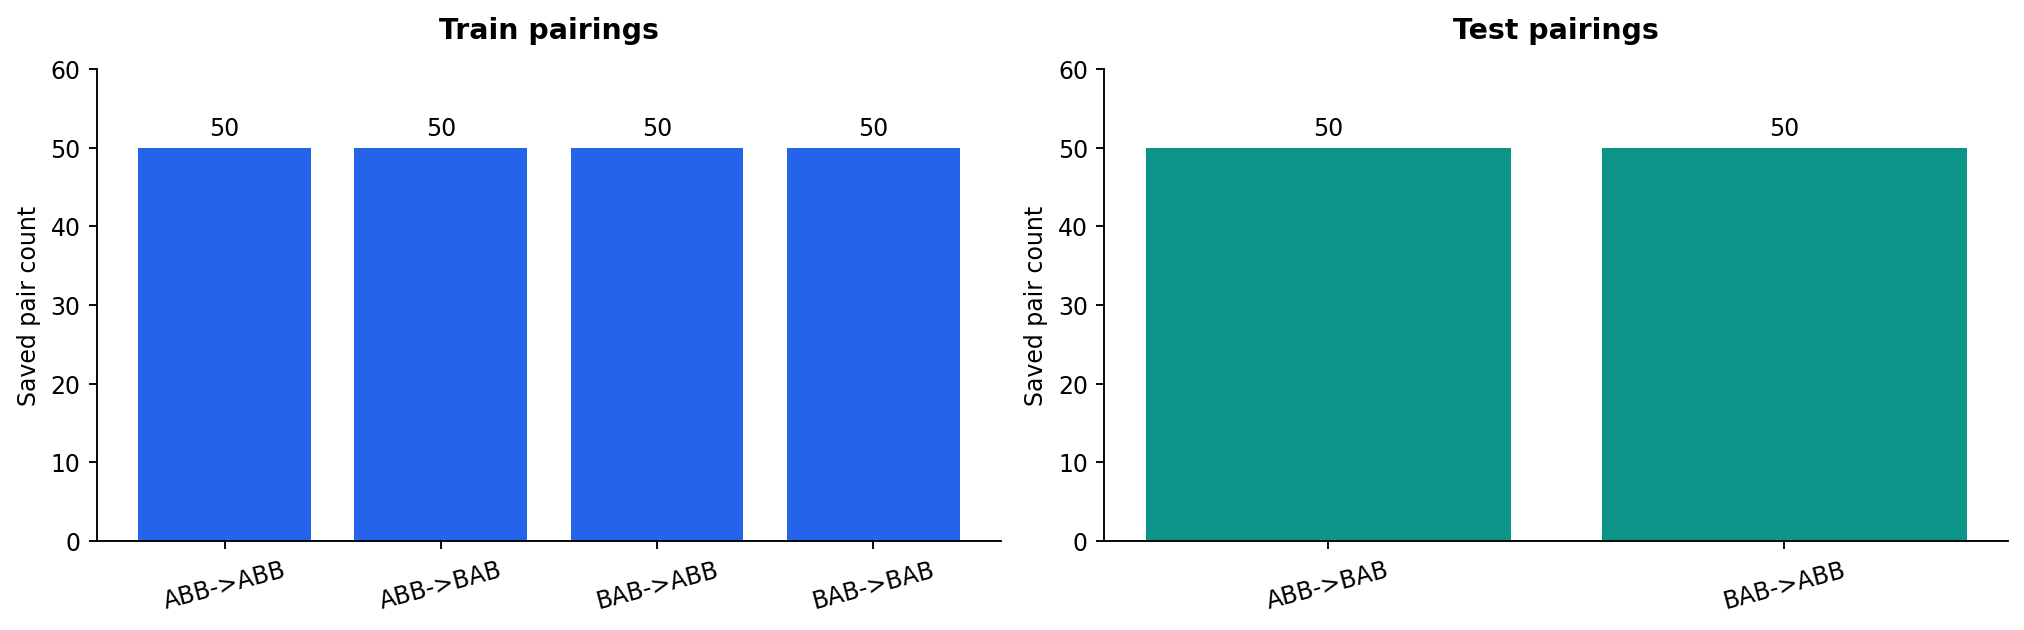

In [3]:
inventory = []
for split, records in pairs.items():
    counts = {}
    for pair in records:
        key = f"{pair.base.pattern}->{pair.source.pattern}"
        counts[key] = counts.get(key, 0) + 1
    for pairing, count in counts.items():
        inventory.append({"split": split, "pairing": pairing, "pairs": count})
pairing_counts = pd.DataFrame(inventory)
display(pairing_counts)
asset_dir = ROOT / "vendor/pyvene_upstream/tutorials/advanced_tutorials/tutorial_data"
assets = {name: read_json(asset_dir / f"{name}.json") for name in ("names", "objects", "places", "templates")}
split_table = []
for name, values in assets.items():
    first = 2 if name == "templates" else len(values) // 2
    split_table.append({"asset": name, "train_entries": first, "test_entries": len(values) - first,
                        "disjoint": not bool(set(values[:first]) & set(values[first:]))})
display(pd.DataFrame(split_table))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, split in zip(axes, ("train", "test")):
    table = pairing_counts[pairing_counts["split"] == split]
    bars = ax.bar(table["pairing"], table["pairs"], color=COLORS["factual"] if split == "train" else COLORS["counterfactual"])
    ax.bar_label(bars, padding=3)
    ax.set(title=f"{split.title()} pairings", ylabel="Saved pair count", ylim=(0, 60))
    ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
show_figure(fig, "01_dataset_pairings")

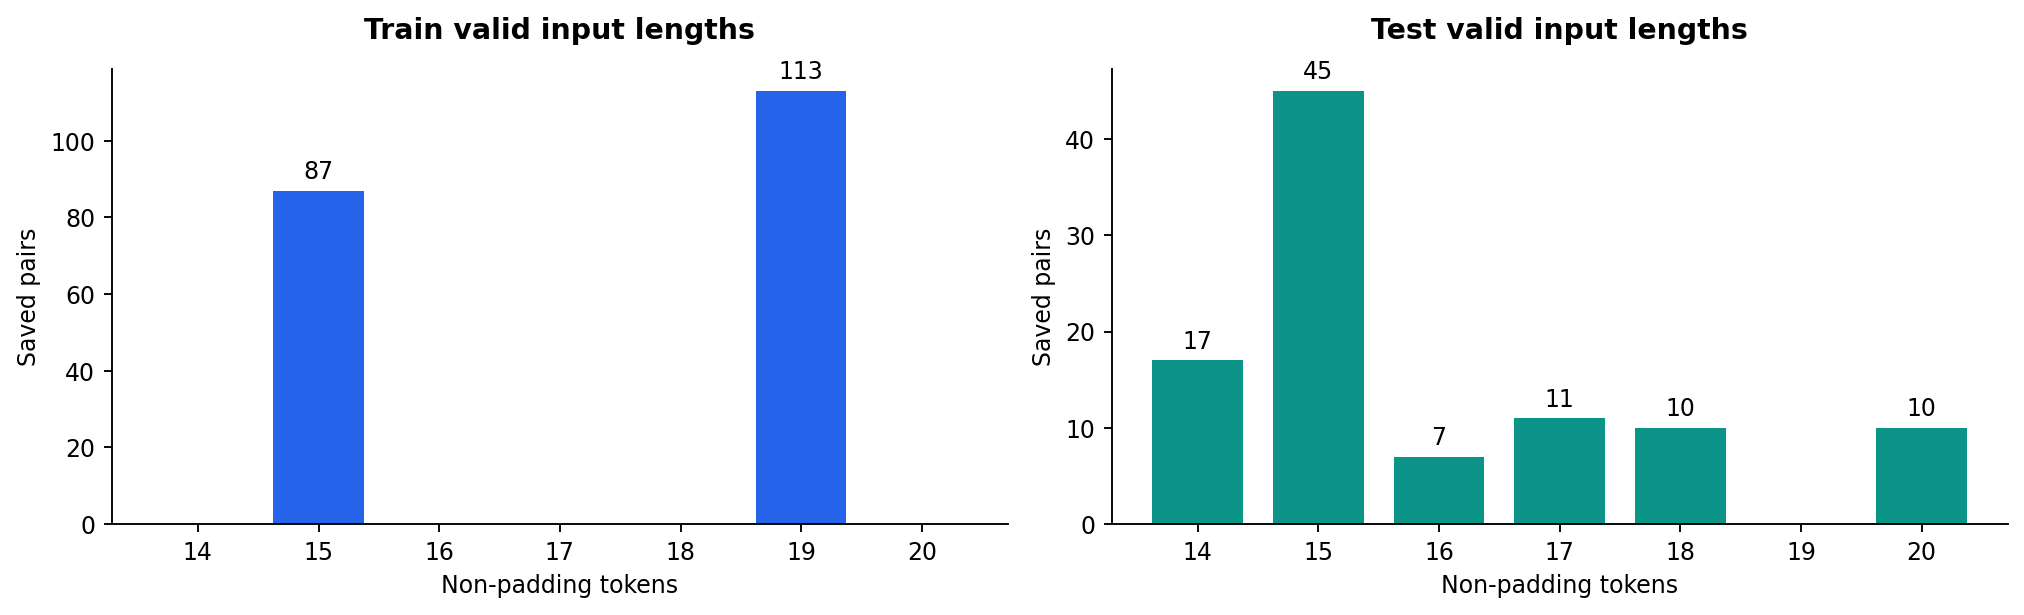

In [4]:
length_tables = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), sharex=True)
for ax, split in zip(axes, ("train", "test")):
    length_tables[split] = frames[split].groupby("base_valid_length").size().sort_index()
    lengths = length_tables[split]
    bars = ax.bar(lengths.index, lengths.values, width=.75,
                  color=COLORS["factual"] if split == "train" else COLORS["counterfactual"])
    ax.bar_label(bars, padding=3)
    ax.set(title=f"{split.title()} valid input lengths", xlabel="Non-padding tokens", ylabel="Saved pairs")
    ax.set_xticks(range(14, 21))
fig.tight_layout()
show_figure(fig, "02_original_prompt_lengths")

## 3. Follow one real pair: roles, names, and the counterfactual

Change SAMPLE_ID below to inspect another saved example.
IO means the factual indirect object; S1/S2 are the first/second occurrences
of the subject. These are occurrence roles, not token IDs.

For train-0050, base names are Elizabeth, Justin, Justin. Source names are
Justin, Elizabeth, Justin. Factual IO is Elizabeth on both sides. Source IO
is the second name, so its POSITION variable selects the second base name,
Justin, as the counterfactual answer.

**GOAL_NAME remains the factual input IO. It is not the counterfactual
target.** Phase 2 actually intervenes at N; GOAL_NAME is shown for inspection.

In [5]:
SAMPLE_ID = "train-0050"
pair = pair_by_id[SAMPLE_ID]
audit = audit_by_id[SAMPLE_ID]
def prompt_card(side, prompt):
    rendered = []
    previous = 0
    role_colors = {"IO": COLORS["factual"], "S1": COLORS["subject"], "S2": COLORS["subject"]}
    for occurrence in prompt.occurrences:
        start, end = occurrence.char_span
        rendered.append(html.escape(prompt.text[previous:start]))
        rendered.append(
            f'<span style="background:{role_colors[occurrence.role]}18;color:{role_colors[occurrence.role]};'
            f'padding:3px 5px;border-radius:4px;border-bottom:2px solid {role_colors[occurrence.role]}">'
            f'{html.escape(prompt.text[start:end])}<sup> {occurrence.role}</sup></span>')
        previous = end
    rendered.append(html.escape(prompt.text[previous:]))
    return f'<div style="padding:15px;margin:8px 0;border:1px solid #dce2eb;border-radius:8px;"><b>{side}</b><p>{"".join(rendered)}</p></div>'
display(HTML(prompt_card("Base", pair.base) + prompt_card("Source", pair.source)))
roles = [{"side": side, "pattern": prompt.pattern, "names": ", ".join(prompt.names),
          "factual_IO": prompt.io_name, "subject": prompt.subject_name,
          "IO_name_order": prompt.io_pos, "S1_name_order": prompt.s1_pos}
         for side, prompt in (("base", pair.base), ("source", pair.source))]
display(pd.DataFrame(roles))
assert pair.counterfactual_answer == pair.base.names[pair.source.io_pos]
print(f"Apply source IO name-order index {pair.source.io_pos} to base.names.")
print("Counterfactual answer:", pair.counterfactual_answer)
print("Factual answer / GOAL_NAME:", pair.base.io_name)

Apply source IO name-order index 1 to base.names.
Counterfactual answer: Justin
Factual answer / GOAL_NAME: Elizabeth


,side,pattern,names,factual_IO,subject,IO_name_order,S1_name_order
0,base,ABB,"Elizabeth, Justin, Justin",Elizabeth,Justin,0,1
1,source,BAB,"Justin, Elizabeth, Justin",Elizabeth,Justin,1,0


## 4. Token spans and positions are per input

Character spans were captured while inserting names into the template.
GPT-2 fast-tokenizer offsets mapped them to complete token spans, which were
verified against the corresponding slow tokenizer. S1 and S2 remain distinct
even when they contain the same name. Token and character spans are half-open:
start is included and stop is excluded.

A scalar name anchor selects the last token of its full span. For right
padding, $N=\sum attention\_mask-1$. Resolve every side independently.
The following cell calls the actual positions module on saved encodings,
without loading a tokenizer or language model.

,side,valid_length,GOAL_NAME,S1,S2,N,N-1,N-2
0,base,19,2,4,14,18,17,16
1,source,19,4,2,14,18,17,16


,side,index,token_id,readable_token,characters,role
0,base,0,6423,Then,"(0, 4)",
1,base,1,11,",","(4, 5)",
2,base,2,10674,ĠElizabeth,"(5, 15)",IO
3,base,3,290,Ġand,"(15, 19)",
4,base,4,10799,ĠJustin,"(19, 26)",S1
5,base,5,550,Ġhad,"(26, 30)",
6,base,6,257,Ġa,"(30, 32)",
7,base,7,1256,Ġlot,"(32, 36)",
8,base,8,286,Ġof,"(36, 39)",
9,base,9,1257,Ġfun,"(39, 43)",


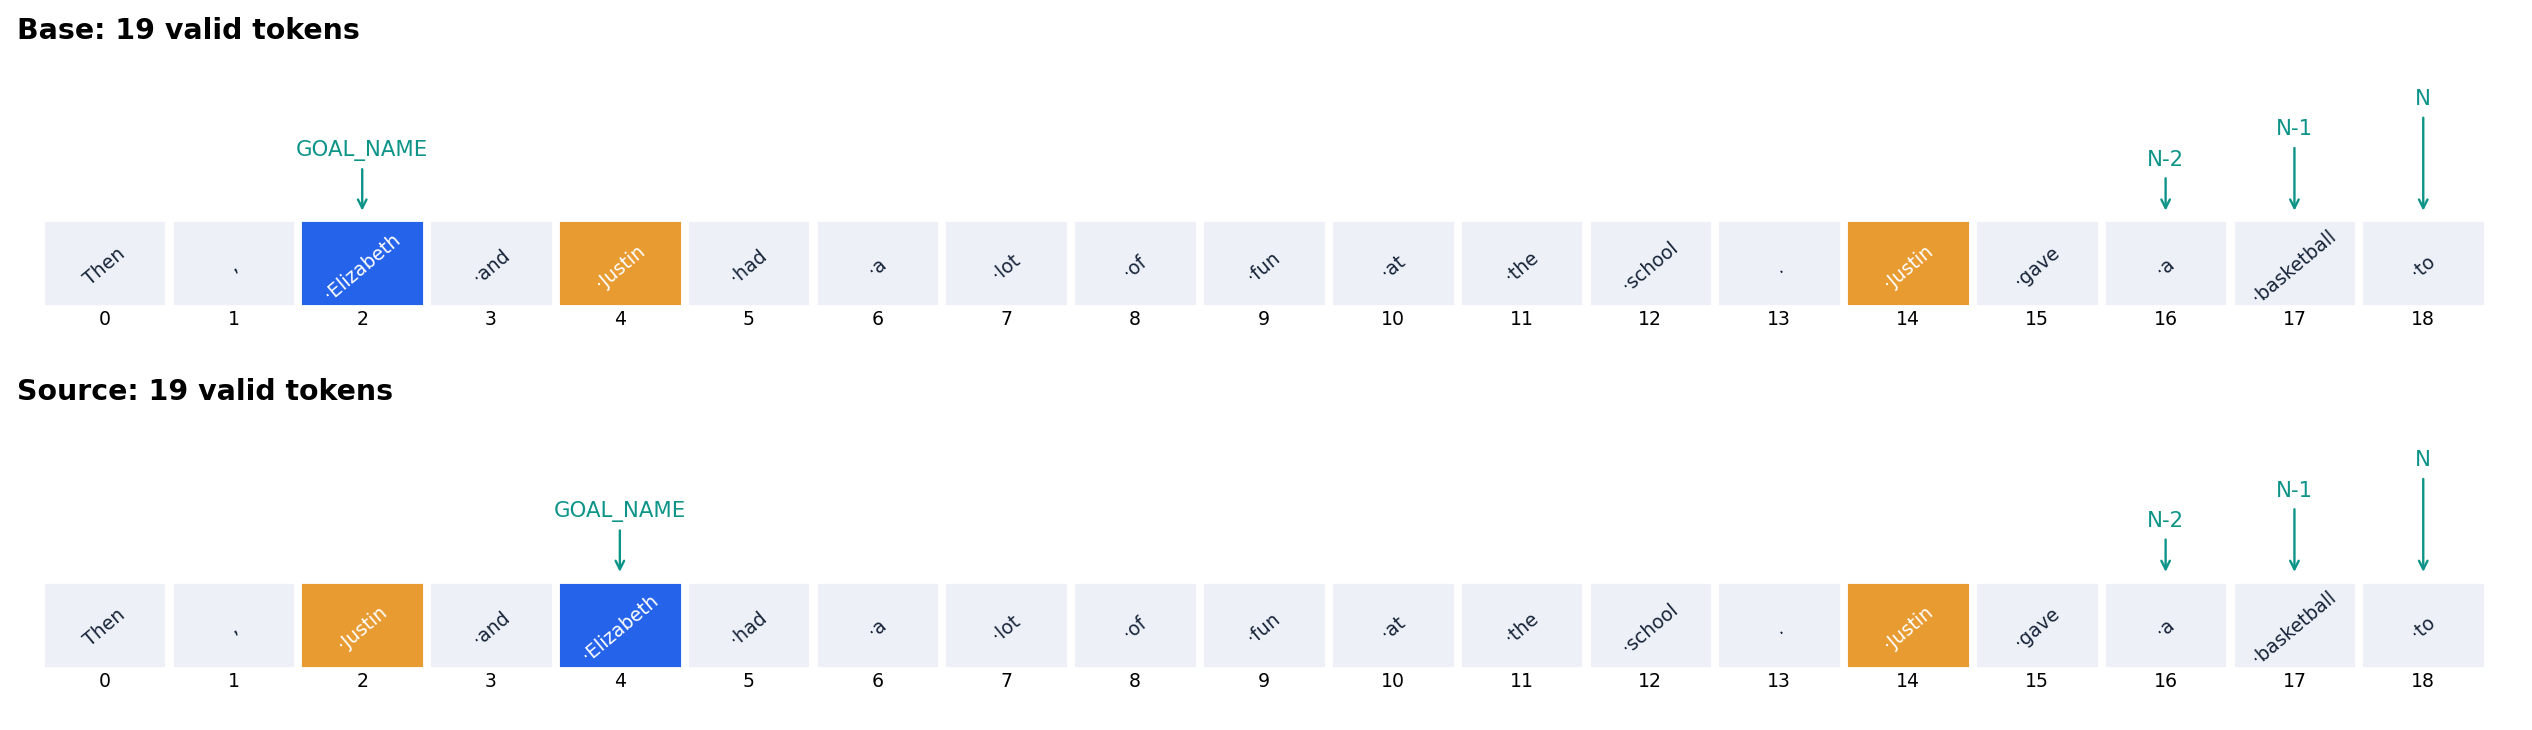

In [6]:
encoded_by_side = {}
position_rows = []
token_rows = []
for side in ("base", "source"):
    record = audit[side]
    spans = {role: NameTokenSpan(name=value["name"], field=value["field"],
                               occurrence=value["occurrence"], char_span=tuple(value["char_span"]),
                               token_span=tuple(value["token_span"]))
             for role, value in record["name_spans"].items()}
    encoded = EncodedPrompt(SAMPLE_ID, side, getattr(pair, side),
                            tuple(record["input_ids"]), tuple(record["readable_tokens"]),
                            tuple(record["attention_mask"]), tuple(tuple(v) for v in record["offsets"]), spans)
    encoded_by_side[side] = encoded
    resolved = {location: resolve_position(encoded, location)
                for location in ("GOAL_NAME", "S1", "S2", "N", "N-1", "N-2")}
    assert all(resolved[name] == record["positions"][name] for name in record["positions"])
    position_rows.append({"side": side, "valid_length": encoded.valid_length, **resolved})
    for index, (token_id, token, offset) in enumerate(zip(encoded.input_ids, encoded.readable_tokens, encoded.offsets)):
        role = ",".join(role for role, span in spans.items() if span.token_span[0] <= index < span.token_span[1])
        token_rows.append({"side": side, "index": index, "token_id": token_id, "readable_token": token,
                           "characters": offset, "role": role})
display(pd.DataFrame(position_rows))
display(pd.DataFrame(token_rows))
fig, axes = plt.subplots(2, 1, figsize=(15, 4.4))
for ax, side in zip(axes, ("base", "source")):
    encoded = encoded_by_side[side]
    for index, token in enumerate(encoded.readable_tokens):
        roles_here = [role for role, span in encoded.name_spans.items()
                      if span.token_span[0] <= index < span.token_span[1]]
        role = roles_here[0] if roles_here else ""
        color = COLORS["factual"] if role == "IO" else COLORS["subject"] if role else "#edf1f7"
        ax.add_patch(Rectangle((index, 0), .96, .85, facecolor=color, edgecolor="white", linewidth=1.2))
        label = token.replace("Ġ", "·")
        ax.text(index + .48, .4, label, ha="center", va="center", fontsize=8,
                rotation=40, color="white" if role else COLORS["ink"])
        ax.text(index + .48, -.18, str(index), ha="center", fontsize=8)
    for location, y in (("GOAL_NAME", 1.5), ("N-2", 1.4), ("N-1", 1.7), ("N", 2.0)):
        index = resolve_position(encoded, location)
        ax.annotate(location, xy=(index + .48, .9), xytext=(index + .48, y),
                    ha="center", fontsize=9, color=COLORS["counterfactual"],
                    arrowprops={"arrowstyle": "->", "color": COLORS["counterfactual"]})
    ax.set_xlim(-.2, len(encoded.input_ids) + .2)
    ax.set_ylim(-.45, 2.35)
    ax.set_title(f"{side.title()}: {encoded.valid_length} valid tokens", loc="left")
    ax.axis("off")
fig.tight_layout()
show_figure(fig, "03_selected_pair_token_positions")

## 5. What the rank-1 intervention does

Let $h_b,h_s$ be the base/source activations at each side's N after block 8,
and let $R$ be the learned $768\times1$ orthonormal projection:

$$h'_b=h_b+\big((h_s-h_b)R\big)R^\mathsf{T}.$$

This replaces the one-dimensional projected coordinate while retaining the
rest of the base activation. GPT-2 blocks 9–11 then compute the next-token
logits, read at **base N**. Only the alignment parameters are optimized.
The frozen downstream model still participates in autograd; freezing its
weights does not mean wrapping training in no_grad.

This diagram is an explanatory schematic. Actual hidden activation vectors
were not saved; no synthetic vector is presented as an observed activation.

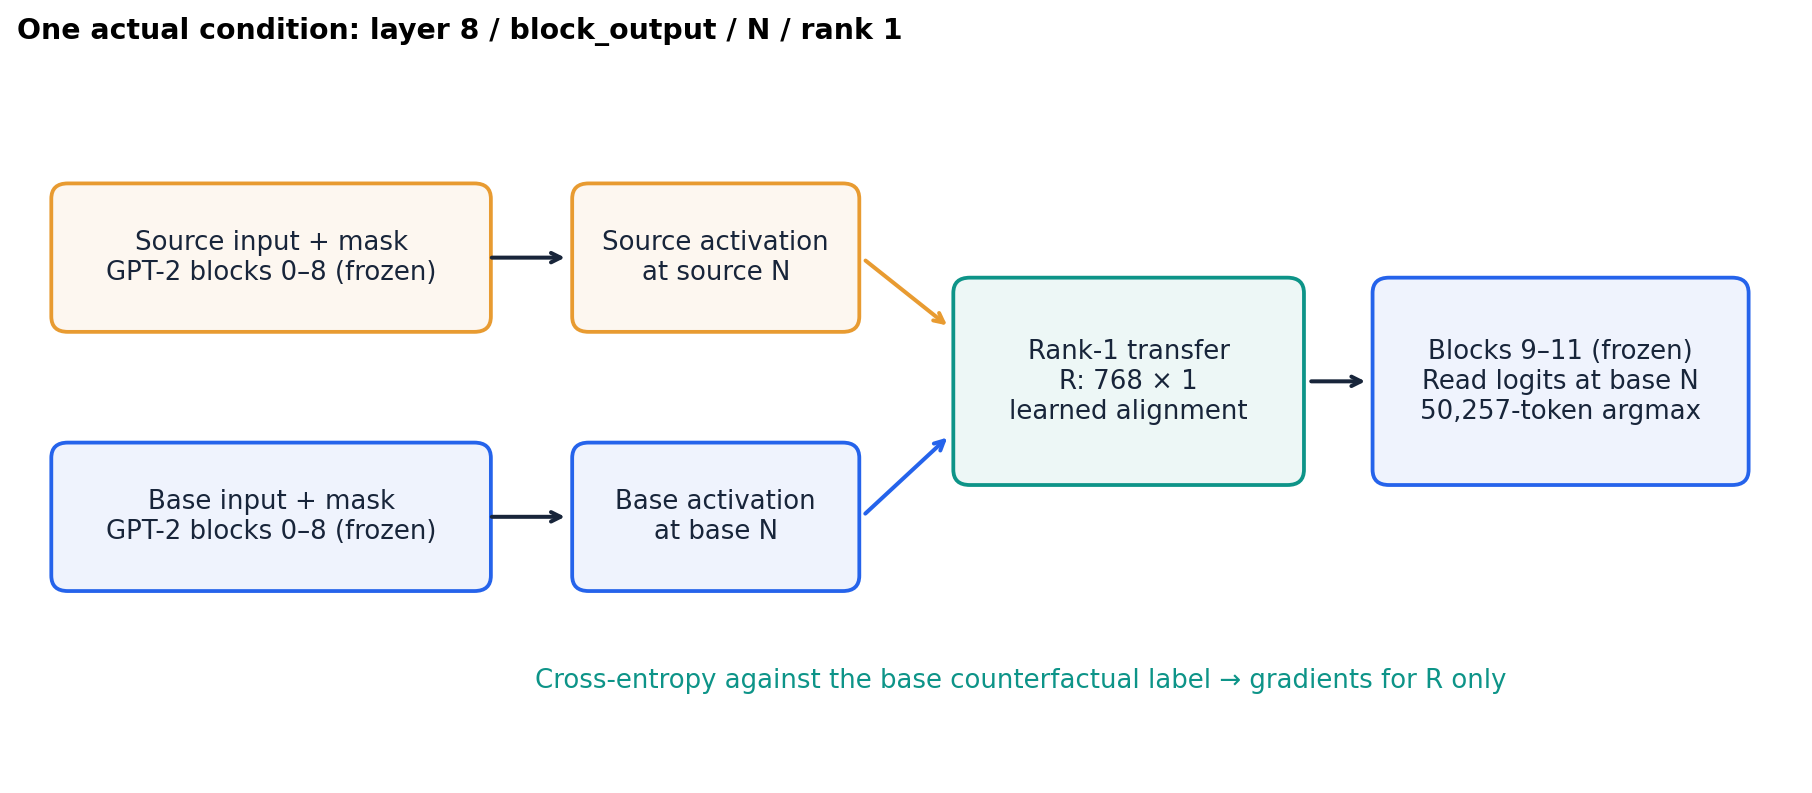

In [7]:
fig, ax = plt.subplots(figsize=(13.5, 5.4))
ax.set(xlim=(0, 14), ylim=(0, 6))
ax.axis("off")
def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=.13",
                               facecolor=color + "12", edgecolor=color, linewidth=1.6))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=11, color=COLORS["ink"])
def arrow(start, end, color=COLORS["ink"]):
    ax.annotate("", xy=end, xytext=start, arrowprops={"arrowstyle": "->", "lw": 1.7, "color": color})
box(.4, 3.9, 3.2, 1.0, "Source input + mask\nGPT-2 blocks 0–8 (frozen)", COLORS["subject"])
box(.4, 1.7, 3.2, 1.0, "Base input + mask\nGPT-2 blocks 0–8 (frozen)", COLORS["factual"])
box(4.5, 3.9, 2.0, 1.0, "Source activation\nat source N", COLORS["subject"])
box(4.5, 1.7, 2.0, 1.0, "Base activation\nat base N", COLORS["factual"])
box(7.5, 2.6, 2.5, 1.5, "Rank-1 transfer\nR: 768 × 1\nlearned alignment", COLORS["counterfactual"])
box(10.8, 2.6, 2.7, 1.5, "Blocks 9–11 (frozen)\nRead logits at base N\n50,257-token argmax", COLORS["factual"])
arrow((3.7, 4.4), (4.35, 4.4))
arrow((3.7, 2.2), (4.35, 2.2))
arrow((6.65, 4.4), (7.35, 3.8), COLORS["subject"])
arrow((6.65, 2.2), (7.35, 2.9), COLORS["factual"])
arrow((10.15, 3.35), (10.65, 3.35))
ax.text(7.9, .75, "Cross-entropy against the base counterfactual label → gradients for R only",
        ha="center", fontsize=11, color=COLORS["counterfactual"])
ax.set_title("One actual condition: layer 8 / block_output / N / rank 1", loc="left")
show_figure(fig, "04_rank1_intervention_flow")

### Inspect the implementation that produced the run

These are source excerpts from the package, not a second notebook
implementation. Expand the blocks to trace batching, the shared masked
intervention forward, training, and evaluation. The viewer never calls
these model-execution functions.

In [8]:
def show_source(filename, function_name):
    source = (ROOT / "src/ioi_das" / filename).read_text(encoding="utf-8")
    node = next(n for n in ast.parse(source).body if isinstance(n, ast.FunctionDef) and n.name == function_name)
    selected = ast.get_source_segment(source, node)
    display(HTML(
        f'<details style="margin:10px 0;"><summary><b>{filename}: {function_name}</b></summary>'
        f'<pre style="max-height:430px;overflow:auto;padding:12px;background:#f4f6fa;">'
        f'{html.escape(selected)}</pre></details>'))
for filename, name in (("intervention.py", "prepare_batch"), ("intervention.py", "intervention_forward"),
                       ("train.py", "train_alignment"), ("evaluate.py", "evaluate_condition")):
    show_source(filename, name)

## 6. Follow all 100 optimizer updates

Adam nominal LR is 0.01. The upstream LinearLR starts at one third of it and
steps **every batch**, with total_iters=10. The effective LR reaches 0.001
after update 10 and stays there for the remaining 90 updates. This preserves
the tutorial's schedule; it is not a ten-epoch decay.

A step's accuracy/loss uses the weights **before that step's update**.
Epoch summaries average those online measurements across changing weights.
Final train evaluation instead holds the last weights fixed for all pairs.
These are different measurements; there are no saved epoch-end checkpoints
or test learning curves.

,step,epoch,batch,loss,correct,total,accuracy,learning_rate_used,learning_rate_next,gradient_norm
0,1,1,1,2.013779,11,20,0.55,0.003333,0.003100,0.123691
1,2,1,2,3.386122,4,20,0.20,0.003100,0.002867,0.861526
2,3,1,3,2.696808,8,20,0.40,0.002867,0.002633,1.525189
3,4,1,4,2.320209,10,20,0.50,0.002633,0.002400,2.522689
4,5,1,5,1.783376,13,20,0.65,0.002400,0.002167,1.730456
5,6,1,6,1.872839,8,20,0.40,0.002167,0.001933,3.136198
6,7,1,7,1.598170,13,20,0.65,0.001933,0.001700,2.238419
7,8,1,8,1.956633,11,20,0.55,0.001700,0.001467,1.943481
8,9,1,9,1.684032,12,20,0.60,0.001467,0.001233,2.549971
9,10,1,10,1.797234,8,20,0.40,0.001233,0.001000,4.172411


,accuracy,correct,epoch,mean_loss,total
0,0.490,98,1,2.110920,200
1,0.590,118,2,1.450841,200
2,0.715,143,3,1.190833,200
3,0.790,158,4,1.078034,200
4,0.835,167,5,1.016407,200
5,0.850,170,6,0.982017,200
6,0.855,171,7,0.962212,200
7,0.860,172,8,0.949781,200
8,0.860,172,9,0.940897,200
9,0.860,172,10,0.933642,200


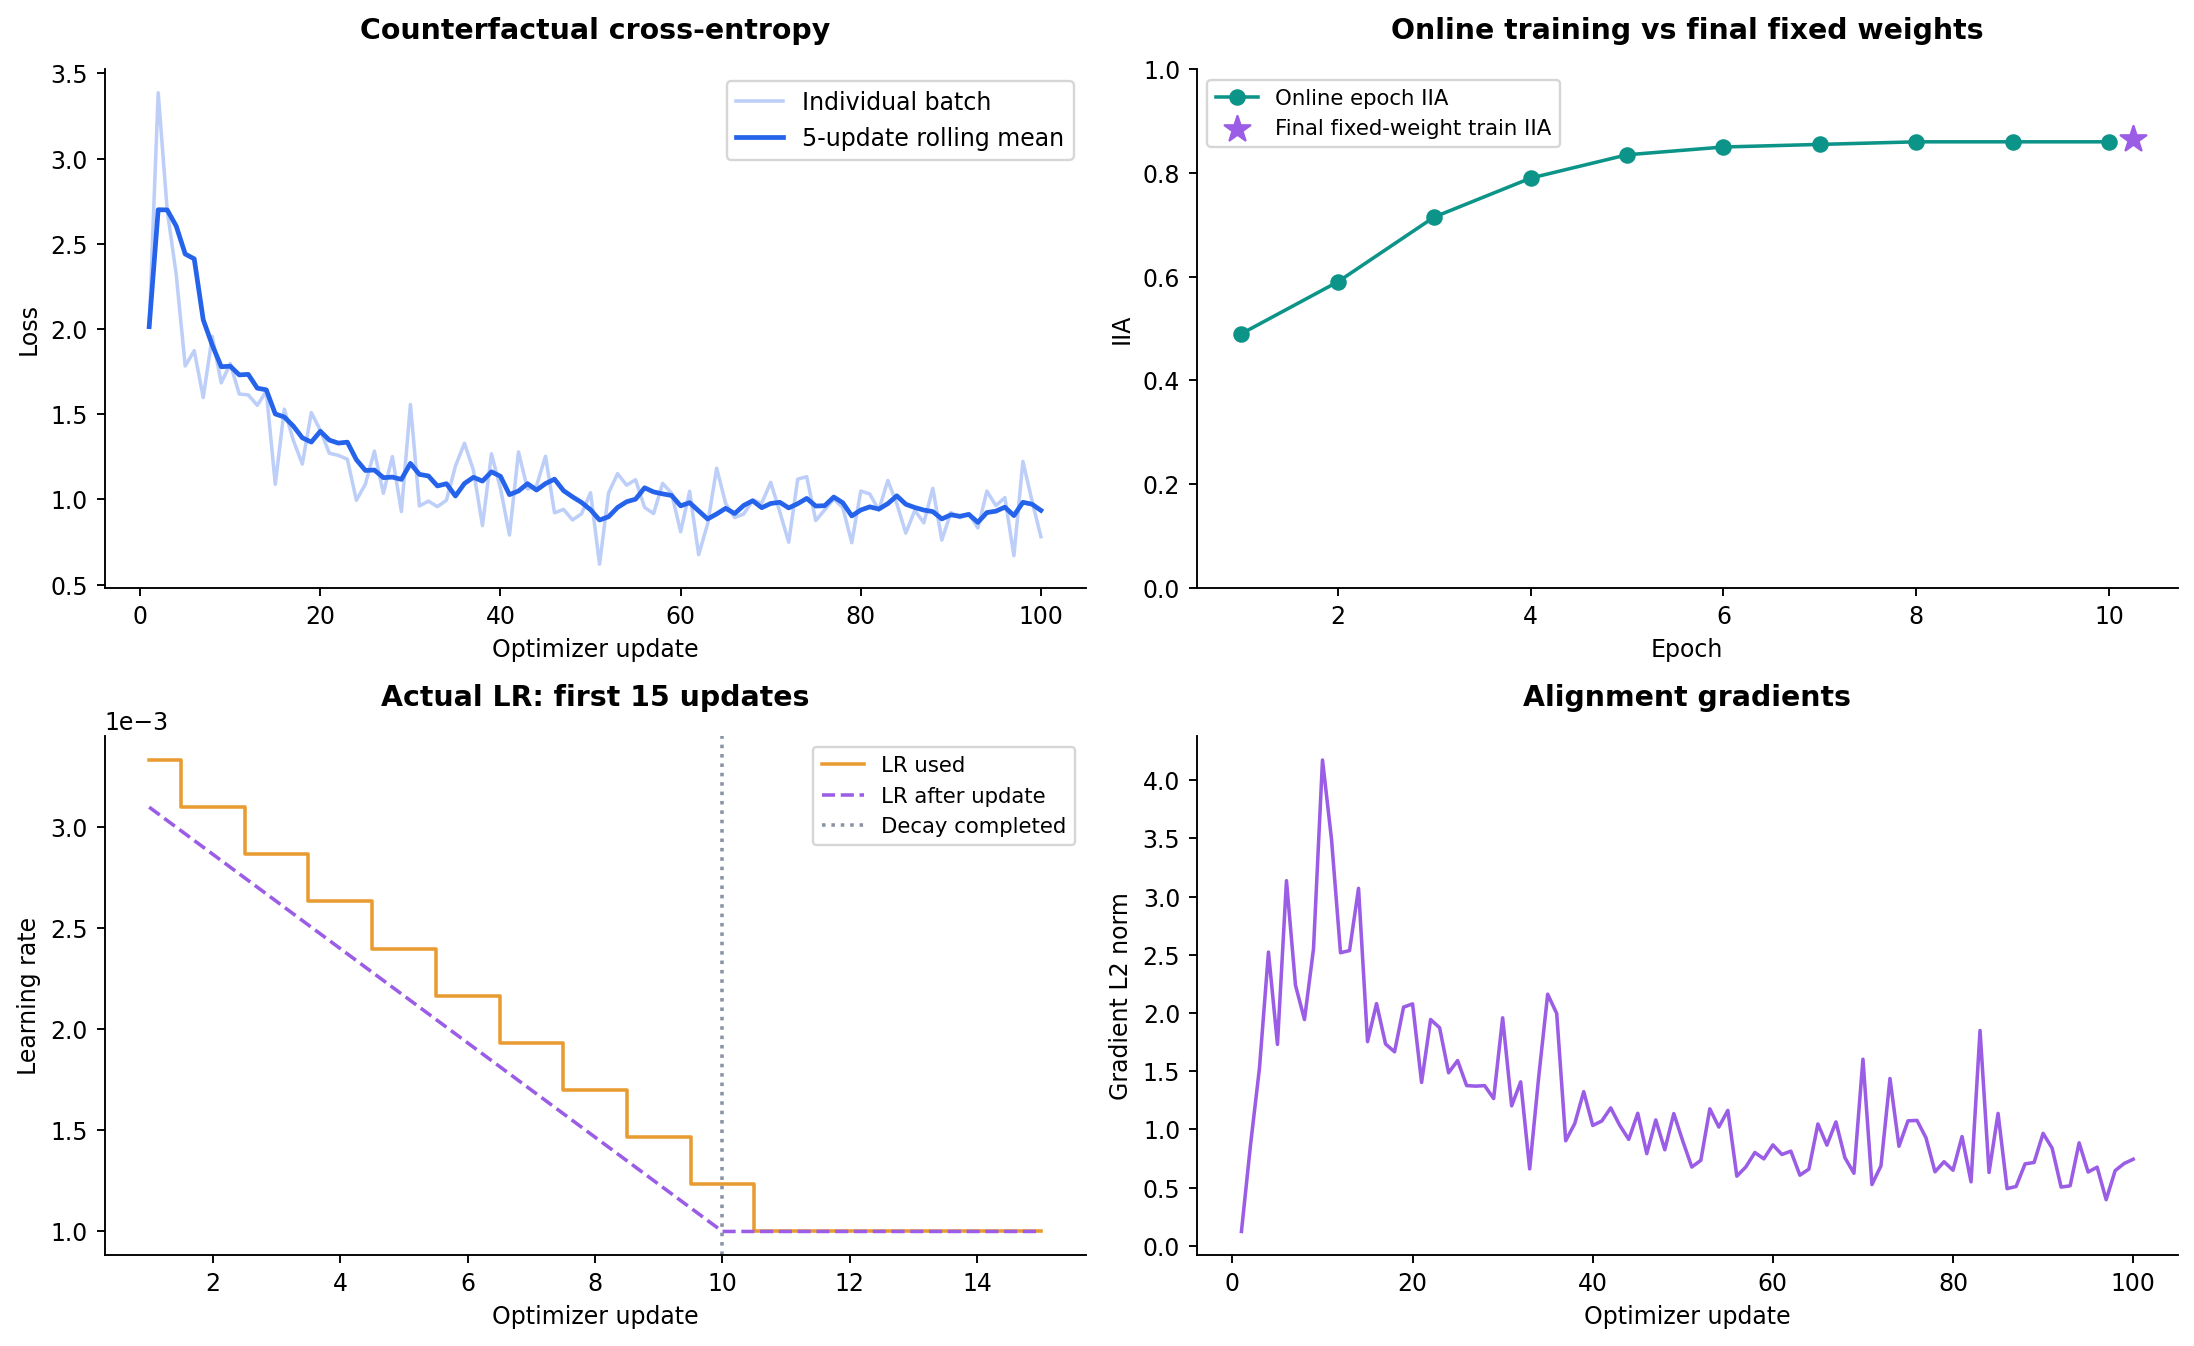

In [9]:
assert len(steps) == 100 and int(steps["total"].sum()) == 2000
assert np.isfinite(steps["gradient_norm"]).all() and (steps["gradient_norm"] > 0).all()
display(steps[["step", "epoch", "batch", "loss", "correct", "total", "accuracy",
               "learning_rate_used", "learning_rate_next", "gradient_norm"]].head(12))
display(epochs)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
ax = axes[0, 0]
ax.plot(steps["step"], steps["loss"], color=COLORS["factual"], alpha=.3, label="Individual batch")
ax.plot(steps["step"], steps["loss"].rolling(5, min_periods=1).mean(),
        color=COLORS["factual"], lw=2, label="5-update rolling mean")
ax.set(title="Counterfactual cross-entropy", xlabel="Optimizer update", ylabel="Loss")
ax.legend()
ax = axes[0, 1]
ax.plot(epochs["epoch"], epochs["accuracy"], "o-", color=COLORS["counterfactual"], label="Online epoch IIA")
ax.scatter([10.25], [metrics["train"]["iia"]], marker="*", s=130, color=COLORS["other"],
           label="Final fixed-weight train IIA")
ax.set(title="Online training vs final fixed weights", xlabel="Epoch", ylabel="IIA", ylim=(0, 1))
ax.legend(fontsize=9)
ax = axes[1, 0]
first = steps.head(15)
ax.step(first["step"], first["learning_rate_used"], where="mid", color=COLORS["subject"], label="LR used")
ax.plot(first["step"], first["learning_rate_next"], "--", color=COLORS["other"], label="LR after update")
ax.axvline(10, color="#8993a4", linestyle=":", label="Decay completed")
ax.set(title="Actual LR: first 15 updates", xlabel="Optimizer update", ylabel="Learning rate")
ax.ticklabel_format(axis="y", style="sci", scilimits=(-3, -3))
ax.legend(fontsize=9)
ax = axes[1, 1]
ax.plot(steps["step"], steps["gradient_norm"], color=COLORS["other"])
ax.set(title="Alignment gradients", xlabel="Optimizer update", ylabel="Gradient L2 norm")
fig.tight_layout()
show_figure(fig, "05_training_trace")

In [10]:
presentation_counts = pd.Series([sample_id for ids in steps["sample_ids"] for sample_id in ids]).value_counts()
assert set(presentation_counts.index) == {p.sample_id for p in pairs["train"]}
assert (presentation_counts == 10).all()
print(f"{len(steps)} updates; {len(epochs)} epochs; {int(steps['total'].sum())} presentations.")
print("Every saved training pair appeared exactly ten times.")
print("First LR used:", steps.iloc[0]["learning_rate_used"])
print("Final LR:", training["final_learning_rate"])
print("Online epoch 10 IIA:", int(epochs.iloc[-1]["correct"]), "/", int(epochs.iloc[-1]["total"]))
print("Fixed final train IIA:", metrics["train"]["iia_correct"], "/", metrics["train"]["iia_total"])
# Change this value to inspect the exact examples used in any update.
STEP_TO_INSPECT = 1
selected_step = steps.loc[steps["step"] == STEP_TO_INSPECT].iloc[0]
display(pd.DataFrame([
    {"sample_id": sample_id, "base_pattern": pair_by_id[sample_id].base.pattern,
     "source_pattern": pair_by_id[sample_id].source.pattern,
     "counterfactual_answer": pair_by_id[sample_id].counterfactual_answer}
    for sample_id in selected_step["sample_ids"]
]))

100 updates; 10 epochs; 2000 presentations.
Every saved training pair appeared exactly ten times.
First LR used: 0.003333333333333333
Final LR: 0.0010000000000000002
Online epoch 10 IIA: 172 / 200
Fixed final train IIA: 173 / 200


,sample_id,base_pattern,source_pattern,counterfactual_answer
0,train-0095,ABB,BAB,Christopher
1,train-0015,ABB,ABB,Nicole
2,train-0030,ABB,ABB,Matthew
3,train-0158,BAB,BAB,Eric
4,train-0128,BAB,ABB,Michael
5,train-0115,BAB,ABB,Robert
6,train-0069,ABB,BAB,Richard
7,train-0170,BAB,BAB,Stephanie
8,train-0174,BAB,BAB,Nicholas
9,train-0045,ABB,ABB,Robert


## 7. Recompute evaluations from saved per-example predictions

Accuracy and IIA use **argmax over the full vocabulary**, not a choice
between two names. Counters below are recomputed from the saved rows and
compared with metrics.json. Display rounding does not change saved values.

Initial-train and final-train evaluations exist. Initial-test predictions
were not saved, so this notebook does not invent a before/after test curve.

,stage,metric,correct,total,ratio
0,initial_train,Factual accuracy,190,200,0.950
1,initial_train,IIA,94,200,0.470
2,train,Factual accuracy,190,200,0.950
3,train,IIA,173,200,0.865
4,test,Factual accuracy,98,100,0.980
5,test,IIA,79,100,0.790


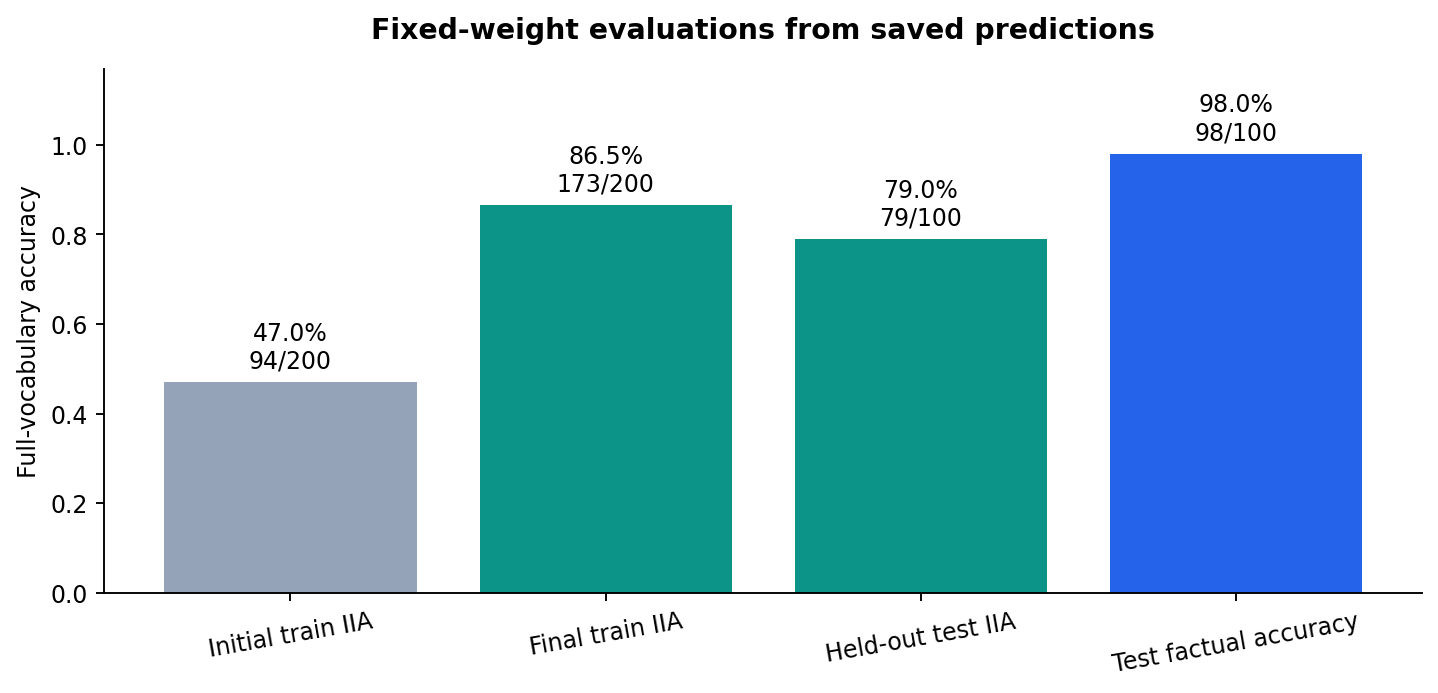

In [11]:
metric_rows = []
for stage, frame in frames.items():
    for label, correctness, numerator, denominator, ratio in (
        ("Factual accuracy", "factual_correct", "factual_correct", "factual_total", "factual_accuracy"),
        ("IIA", "counterfactual_correct", "iia_correct", "iia_total", "iia"),
    ):
        correct = int(frame[correctness].sum())
        total = len(frame)
        assert correct == metrics[stage][numerator] and total == metrics[stage][denominator]
        assert correct / total == metrics[stage][ratio]
        metric_rows.append({"stage": stage, "metric": label, "correct": correct,
                            "total": total, "ratio": correct / total})
metric_table = pd.DataFrame(metric_rows)
display(metric_table)
fig, ax = plt.subplots(figsize=(10, 4))
labels = ["Initial train IIA", "Final train IIA", "Held-out test IIA", "Test factual accuracy"]
values = [metrics["initial_train"]["iia"], metrics["train"]["iia"],
          metrics["test"]["iia"], metrics["test"]["factual_accuracy"]]
counts = [(metrics[stage][correct], metrics[stage][total]) for stage, correct, total in (
    ("initial_train", "iia_correct", "iia_total"), ("train", "iia_correct", "iia_total"),
    ("test", "iia_correct", "iia_total"), ("test", "factual_correct", "factual_total"))]
bars = ax.bar(labels, values, color=["#94a3b8", COLORS["counterfactual"], COLORS["counterfactual"], COLORS["factual"]])
ax.bar_label(bars, labels=[f"{value:.1%}\n{n}/{d}" for value, (n, d) in zip(values, counts)], padding=4)
ax.set(ylabel="Full-vocabulary accuracy", ylim=(0, 1.17), title="Fixed-weight evaluations from saved predictions")
ax.tick_params(axis="x", rotation=10)
show_figure(fig, "06_final_metrics")

,stage,pairing,correct,total,IIA
0,initial_train,ABB->ABB,46,50,0.92
1,initial_train,ABB->BAB,0,50,0.00
2,initial_train,BAB->ABB,0,50,0.00
3,initial_train,BAB->BAB,48,50,0.96
4,train,ABB->ABB,46,50,0.92
5,train,ABB->BAB,35,50,0.70
6,train,BAB->ABB,44,50,0.88
7,train,BAB->BAB,48,50,0.96
8,test,ABB->BAB,32,50,0.64
9,test,BAB->ABB,47,50,0.94


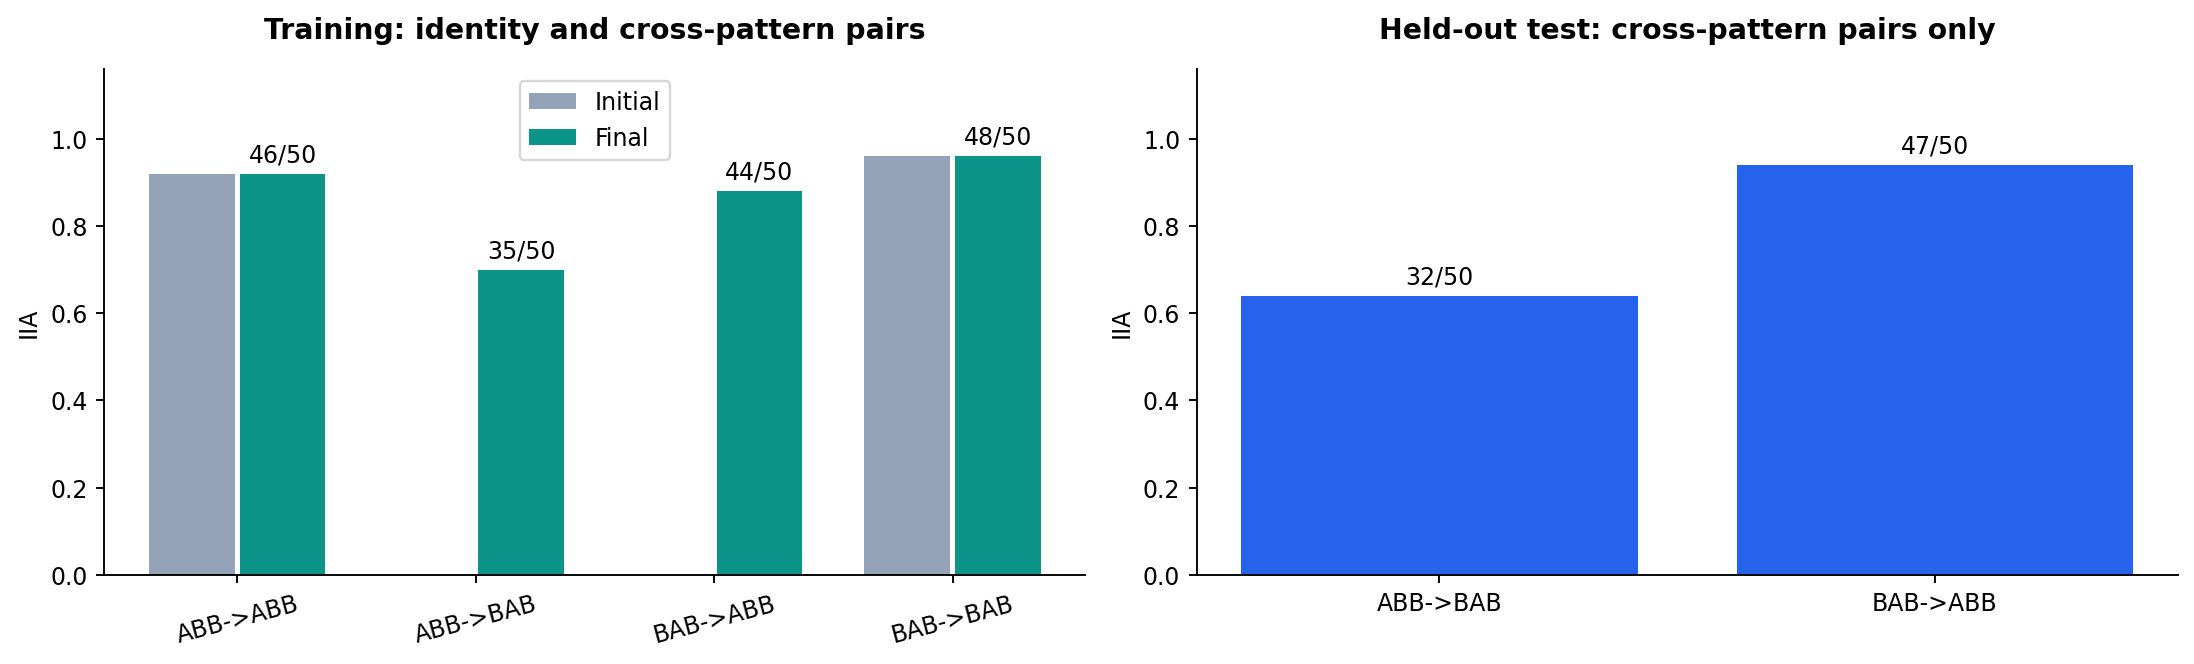

**Identity training pairs:** 100. **Cross-pattern training IIA:** 0/100 → 79/100. Overall train and test scores describe different pairing mixtures.

In [12]:
pairing_rows = []
for stage, frame in frames.items():
    frame["pairing"] = frame["base_pattern"] + "->" + frame["source_pattern"]
    for pairing, group in frame.groupby("pairing", sort=True):
        pairing_rows.append({"stage": stage, "pairing": pairing, "correct": int(group["counterfactual_correct"].sum()),
                             "total": len(group), "IIA": group["counterfactual_correct"].mean()})
pairing_scores = pd.DataFrame(pairing_rows)
display(pairing_scores)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = ["ABB->ABB", "ABB->BAB", "BAB->ABB", "BAB->BAB"]
initial_scores = pairing_scores[pairing_scores["stage"] == "initial_train"].set_index("pairing").reindex(order)
final_scores = pairing_scores[pairing_scores["stage"] == "train"].set_index("pairing").reindex(order)
x = np.arange(4)
axes[0].bar(x - .19, initial_scores["IIA"], .36, label="Initial", color="#94a3b8")
bars = axes[0].bar(x + .19, final_scores["IIA"], .36, label="Final", color=COLORS["counterfactual"])
axes[0].bar_label(bars, labels=[f"{int(n)}/{int(d)}" for n, d in zip(final_scores["correct"], final_scores["total"])], padding=3)
axes[0].set_xticks(x, order, rotation=15)
axes[0].set(title="Training: identity and cross-pattern pairs", ylabel="IIA", ylim=(0, 1.16))
axes[0].legend()
test_scores = pairing_scores[pairing_scores["stage"] == "test"]
bars = axes[1].bar(test_scores["pairing"], test_scores["IIA"], color=COLORS["factual"])
axes[1].bar_label(bars, labels=[f"{int(n)}/{int(d)}" for n, d in zip(test_scores["correct"], test_scores["total"])], padding=3)
axes[1].set(title="Held-out test: cross-pattern pairs only", ylabel="IIA", ylim=(0, 1.16))
fig.tight_layout()
show_figure(fig, "07_pairing_specific_iia")
train = frames["train"]
initial_train = frames["initial_train"]
mixed = train["base_pattern"] != train["source_pattern"]
initial_mixed = initial_train["base_pattern"] != initial_train["source_pattern"]
same = [p for p in pairs["train"] if p.base.pattern == p.source.pattern]
assert all(p.base.text == p.source.text for p in same)
display(Markdown(
    f"**Identity training pairs:** {len(same)}. "
    f"**Cross-pattern training IIA:** "
    f"{int(initial_train.loc[initial_mixed, 'counterfactual_correct'].sum())}/{int(initial_mixed.sum())}"
    f" → {int(train.loc[mixed, 'counterfactual_correct'].sum())}/{int(mixed.sum())}. "
    "Overall train and test scores describe different pairing mixtures."))

## 8. Explore predictions, including successful and unsuccessful changes

Edit EXAMPLE_IDS to compare any saved examples. Target probability is the
probability of the counterfactual name token; it can rise without becoming
the vocabulary argmax. These rows contain saved probabilities, not a
complete top-k distribution. Held-out examples have final results only.

,sample_id,stage,pairing,factual_IO,CF_target,CF_argmax,CF_correct,target_probability,argmax_probability,base_N,source_N
0,train-0050,initial_train,ABB->BAB,Elizabeth,Justin,' Elizabeth',False,0.022469,0.855043,18,18
1,train-0050,train,ABB->BAB,Elizabeth,Justin,' Justin',True,0.489656,0.489656,18,18
2,train-0100,initial_train,BAB->ABB,Elizabeth,Amanda,' Elizabeth',False,0.046322,0.453921,14,14
3,train-0100,train,BAB->ABB,Elizabeth,Amanda,' Amanda',True,0.578057,0.578057,14,14
4,train-0054,initial_train,ABB->BAB,Robert,Ashley,' Robert',False,0.000829,0.800015,14,14
5,train-0054,train,ABB->BAB,Robert,Ashley,' Robert',False,0.118019,0.405703,14,14
6,train-0087,initial_train,ABB->BAB,Amber,Amanda,' the',False,0.064082,0.189611,18,18
7,train-0087,train,ABB->BAB,Amber,Amanda,' Amanda',True,0.280899,0.280899,18,18
8,test-0000,test,ABB->BAB,Rebecca,Jamie,' Jamie',True,0.175088,0.175088,14,14
9,test-0012,test,ABB->BAB,Patrick,Katie,' Patrick',False,0.113834,0.319581,13,13


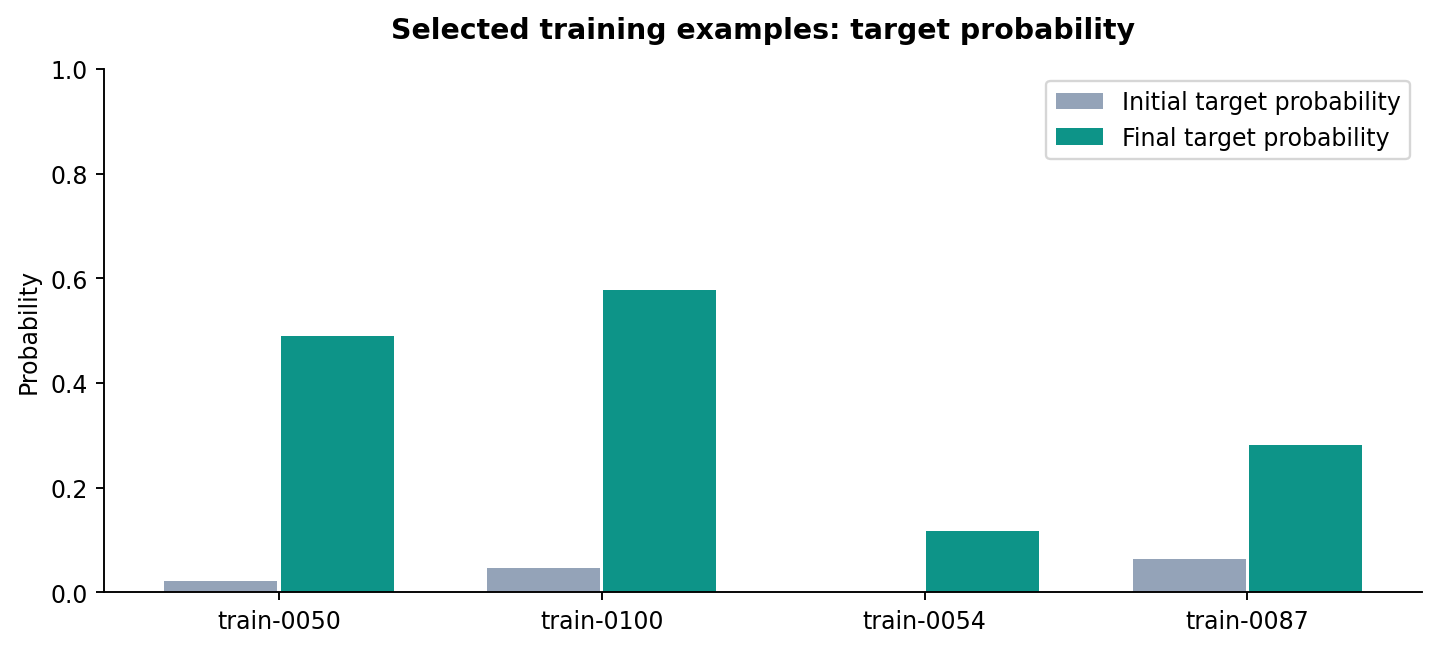

In [13]:
EXAMPLE_IDS = ["train-0050", "train-0100", "train-0054", "train-0087",
               "test-0000", "test-0012", "test-0004", "test-0097"]
unknown_ids = [name for name in EXAMPLE_IDS if name not in pair_by_id]
if unknown_ids:
    raise ValueError(f"Unknown saved sample IDs: {unknown_ids}. Choose IDs from train.jsonl or test.jsonl.")
if not EXAMPLE_IDS:
    raise ValueError("Select at least one saved sample ID in EXAMPLE_IDS.")
explorer_rows = []
for sample_id in EXAMPLE_IDS:
    for stage, frame in frames.items():
        selected = frame[frame["sample_id"] == sample_id]
        if selected.empty:
            continue
        row = selected.iloc[0]
        explorer_rows.append({
            "sample_id": sample_id, "stage": stage, "pairing": row["pairing"],
            "factual_IO": row["base_io_name"], "CF_target": row["counterfactual_target_name"],
            "CF_argmax": repr(row["counterfactual_prediction"]["continuation"]),
            "CF_correct": row["counterfactual_correct"],
            "target_probability": row["counterfactual_target_probability"],
            "argmax_probability": row["counterfactual_prediction_probability"],
            "base_N": row["base_readout_position"], "source_N": row["source_position"],
        })
explorer = pd.DataFrame(explorer_rows)
display(explorer)
comparison_ids = [name for name in EXAMPLE_IDS if name.startswith("train-")]
if comparison_ids:
    comparison = explorer[explorer["sample_id"].isin(comparison_ids)]
    piv = comparison.pivot(index="sample_id", columns="stage", values="target_probability").reindex(comparison_ids)
    fig, ax = plt.subplots(figsize=(10, 4))
    x = np.arange(len(comparison_ids))
    ax.bar(x - .18, piv["initial_train"], .35, label="Initial target probability", color="#94a3b8")
    ax.bar(x + .18, piv["train"], .35, label="Final target probability", color=COLORS["counterfactual"])
    ax.set_xticks(x, comparison_ids)
    ax.set(title="Selected training examples: target probability", ylabel="Probability", ylim=(0, 1))
    ax.legend()
    show_figure(fig, "08_example_target_probabilities")
else:
    display(Markdown("Only held-out examples are selected. Their final results are shown above; "
                     "initial test predictions were not saved, so no before/after chart is drawn."))

In [14]:
# Set this to any ID, then rerun this cell for its complete prompts and saved scores.
DETAIL_ID = "test-0004"
detail_pair = pair_by_id[DETAIL_ID]
display(HTML(prompt_card("Base", detail_pair.base) + prompt_card("Source", detail_pair.source)))
detailed = []
for stage, frame in frames.items():
    rows = frame[frame["sample_id"] == DETAIL_ID]
    if not rows.empty:
        row = rows.iloc[0]
        detailed.append({
            "stage": stage, "factual_target": row["factual_target_name"],
            "factual_argmax": repr(row["factual_prediction"]["continuation"]),
            "CF_target": row["counterfactual_target_name"],
            "CF_argmax": repr(row["counterfactual_prediction"]["continuation"]),
            "target_probability": row["counterfactual_target_probability"],
            "predicted_probability": row["counterfactual_prediction_probability"],
            "CF_loss": row["counterfactual_loss"], "correct": row["counterfactual_correct"],
        })
display(pd.DataFrame(detailed))

,stage,factual_target,factual_argmax,CF_target,CF_argmax,target_probability,predicted_probability,CF_loss,correct
0,test,Mary,' Mary',Nathan,' her',0.153998,0.211132,1.870815,False


## 9. Errors and descriptive length breakdowns

A wrong prediction can retain the base factual IO or choose another token,
such as a pronoun. This is why full-vocabulary evaluation matters.

Length groups have different templates and pairing mixtures, and some are
small. Their scores are descriptive; this plot does not establish that
length caused an error. No held-out result is used here to select another
configuration.

,outcome,count
0,Counterfactual target,79
1,Base factual IO,13
2,Other vocabulary token,8


,other_token,count
0,' her',6
1,' his',2


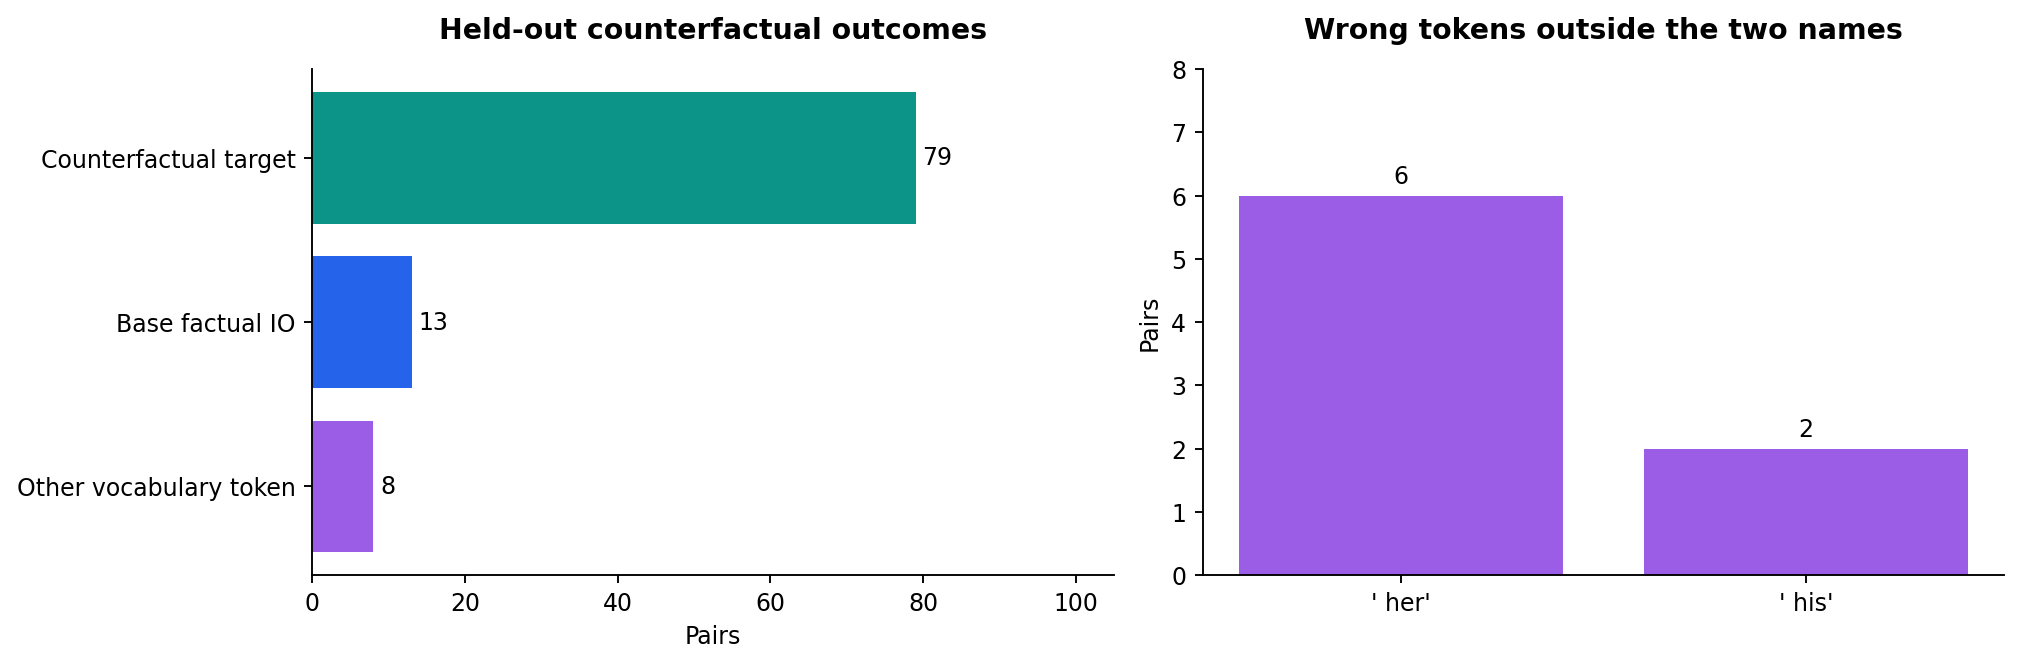

,sample_id,pairing,base_valid_length,counterfactual_target_name,outcome,counterfactual_target_probability
4,test-0004,ABB->BAB,15,Nathan,Other vocabulary token,0.153998
12,test-0012,ABB->BAB,14,Katie,Base factual IO,0.113834
15,test-0015,ABB->BAB,20,Dustin,Other vocabulary token,0.175441
16,test-0016,ABB->BAB,14,Lindsey,Base factual IO,0.144456
18,test-0018,ABB->BAB,15,Mary,Base factual IO,0.014351
22,test-0022,ABB->BAB,14,Emily,Base factual IO,0.157494
23,test-0023,ABB->BAB,18,Kristen,Other vocabulary token,0.131699
24,test-0024,ABB->BAB,14,Lindsay,Base factual IO,0.284842
25,test-0025,ABB->BAB,14,Aaron,Base factual IO,0.137274
30,test-0030,ABB->BAB,17,Christine,Other vocabulary token,0.114056


In [15]:
test = frames["test"].copy()
def outcome(row):
    if row["counterfactual_correct"]:
        return "Counterfactual target"
    if row["counterfactual_prediction"]["token_id"] == row["factual_target_token_id"]:
        return "Base factual IO"
    return "Other vocabulary token"
test["outcome"] = test.apply(outcome, axis=1)
outcome_order = ["Counterfactual target", "Base factual IO", "Other vocabulary token"]
outcome_counts = test["outcome"].value_counts().reindex(outcome_order, fill_value=0)
failures = test[~test["counterfactual_correct"]]
other = failures[failures["outcome"] == "Other vocabulary token"]
other_tokens = other["counterfactual_prediction"].map(lambda value: repr(value["continuation"])).value_counts()
display(pd.DataFrame({"outcome": outcome_counts.index, "count": outcome_counts.values}))
display(pd.DataFrame({"other_token": other_tokens.index, "count": other_tokens.values}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars = axes[0].barh(outcome_order, outcome_counts.values,
                   color=[COLORS["counterfactual"], COLORS["factual"], COLORS["other"]])
axes[0].bar_label(bars, padding=3)
axes[0].set(title="Held-out counterfactual outcomes", xlabel="Pairs", xlim=(0, 105))
axes[0].invert_yaxis()
bars = axes[1].bar(other_tokens.index, other_tokens.values, color=COLORS["other"])
axes[1].bar_label(bars, padding=3)
axes[1].set(title="Wrong tokens outside the two names", ylabel="Pairs", ylim=(0, max(other_tokens.values) + 2))
fig.tight_layout()
show_figure(fig, "09_test_failure_categories")
display(failures[["sample_id", "pairing", "base_valid_length", "counterfactual_target_name",
                  "outcome", "counterfactual_target_probability"]])

,total,iia_correct,factual_correct,IIA
base_valid_length,,,,
14,17,11,17,0.647059
15,45,42,45,0.933333
16,7,6,7,0.857143
17,11,7,11,0.636364
18,10,7,9,0.700000
20,10,6,9,0.600000


correct  total       IIA
base_valid_length pairing                           
14                ABB->BAB        4     10  0.400000
                  BAB->ABB        7      7  1.000000
15                ABB->BAB       18     21  0.857143
                  BAB->ABB       24     24  1.000000
16                ABB->BAB        3      4  0.750000
                  BAB->ABB        3      3  1.000000
17                ABB->BAB        3      5  0.600000
                  BAB->ABB        4      6  0.666667
18                ABB->BAB        3      5  0.600000
                  BAB->ABB        4      5  0.800000
20                ABB->BAB        1      5  0.200000
                  BAB->ABB        5      5  1.000000

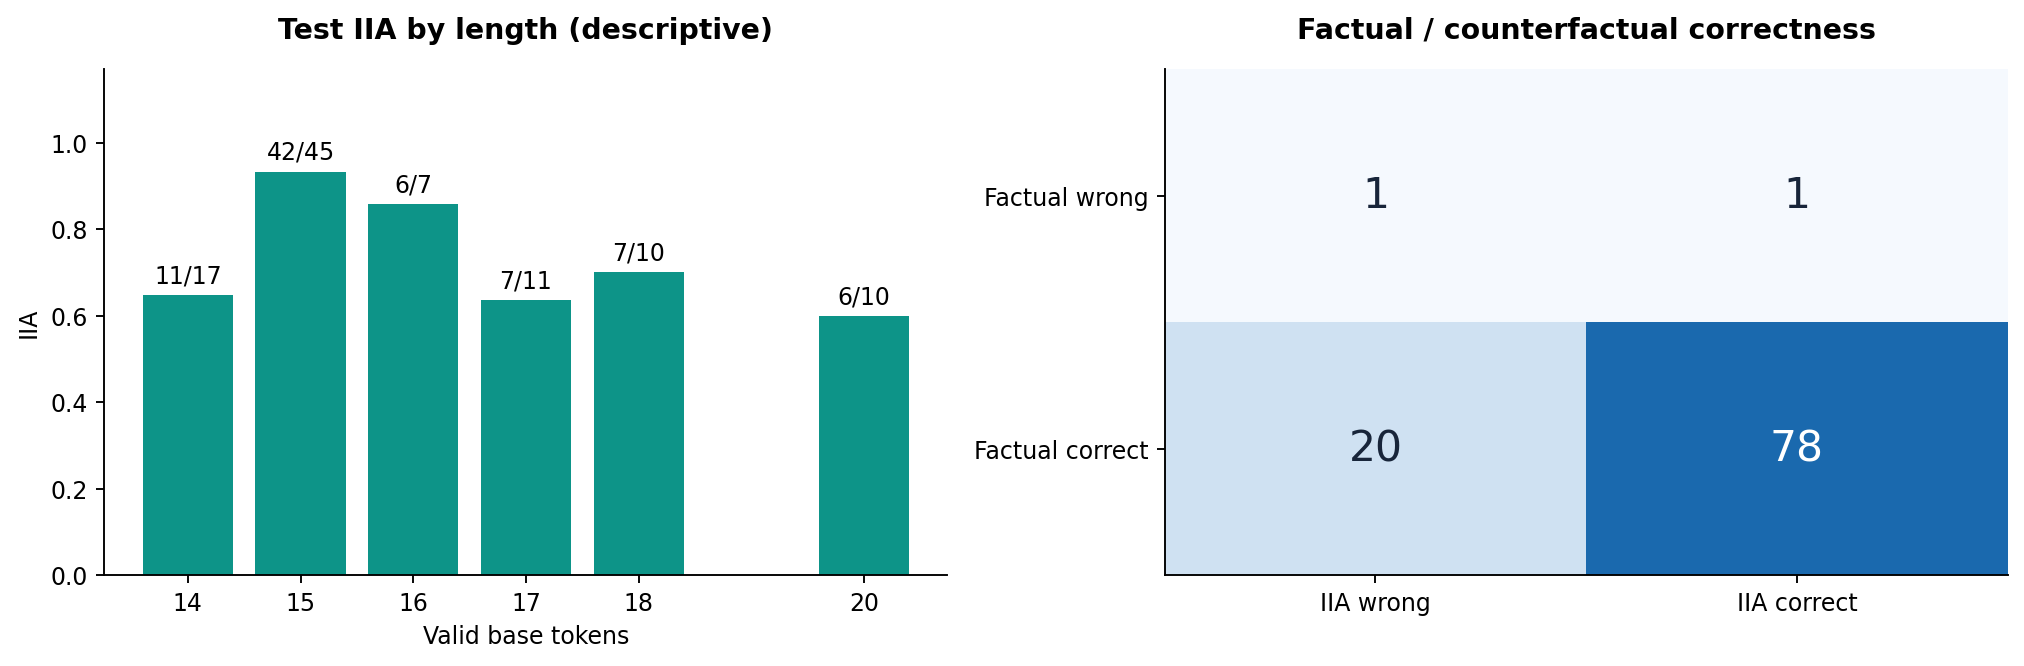

In [16]:
grouped_lengths = test.groupby("base_valid_length").agg(
    total=("sample_id", "size"), iia_correct=("counterfactual_correct", "sum"),
    factual_correct=("factual_correct", "sum"))
grouped_lengths["IIA"] = grouped_lengths["iia_correct"] / grouped_lengths["total"]
display(grouped_lengths)
length_pair = test.groupby(["base_valid_length", "pairing"]).agg(
    correct=("counterfactual_correct", "sum"), total=("sample_id", "size"))
length_pair["IIA"] = length_pair["correct"] / length_pair["total"]
display(length_pair)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars = axes[0].bar(grouped_lengths.index, grouped_lengths["IIA"], color=COLORS["counterfactual"])
axes[0].bar_label(bars, labels=[f"{int(c)}/{int(n)}" for c, n in zip(grouped_lengths["iia_correct"], grouped_lengths["total"])], padding=3)
axes[0].set(title="Test IIA by length (descriptive)", xlabel="Valid base tokens", ylabel="IIA", ylim=(0, 1.17))
axes[0].set_xticks(grouped_lengths.index)
joint = pd.crosstab(test["factual_correct"], test["counterfactual_correct"]).reindex(
    index=[False, True], columns=[False, True], fill_value=0)
axes[1].imshow(joint.values, cmap="Blues", vmin=0, vmax=len(test), aspect="auto")
for y in range(2):
    for x in range(2):
        axes[1].text(x, y, str(joint.iloc[y, x]), ha="center", va="center",
                     color="white" if joint.iloc[y, x] > 50 else COLORS["ink"], fontsize=18)
axes[1].set_xticks([0, 1], ["IIA wrong", "IIA correct"])
axes[1].set_yticks([0, 1], ["Factual wrong", "Factual correct"])
axes[1].set_title("Factual / counterfactual correctness")
fig.tight_layout()
show_figure(fig, "10_length_and_joint_outcomes")

## 10. Inspect the actual saved alignment

The checkpoint contains both the raw orthogonal-parametrization state and
the effective $768\times1$ direction. The cell below reconstructs the
effective weight using PyTorch's same orthogonal parametrization; it does
not instantiate GPT-2 or run a forward pass.

Only initial and final alignment checkpoints exist. No per-step weight
trajectory is inferred. The sign of a direction can flip without changing
its rank-1 projector; individual coordinate values are not standalone
semantic attributions.

,dimensions,rank,initial_norm,final_norm,signed_direction_cosine,sign_invariant_projector_overlap,max_reconstruction_error
0,768,1,1.0,1.0,0.01844,0.00034,1.043081e-07


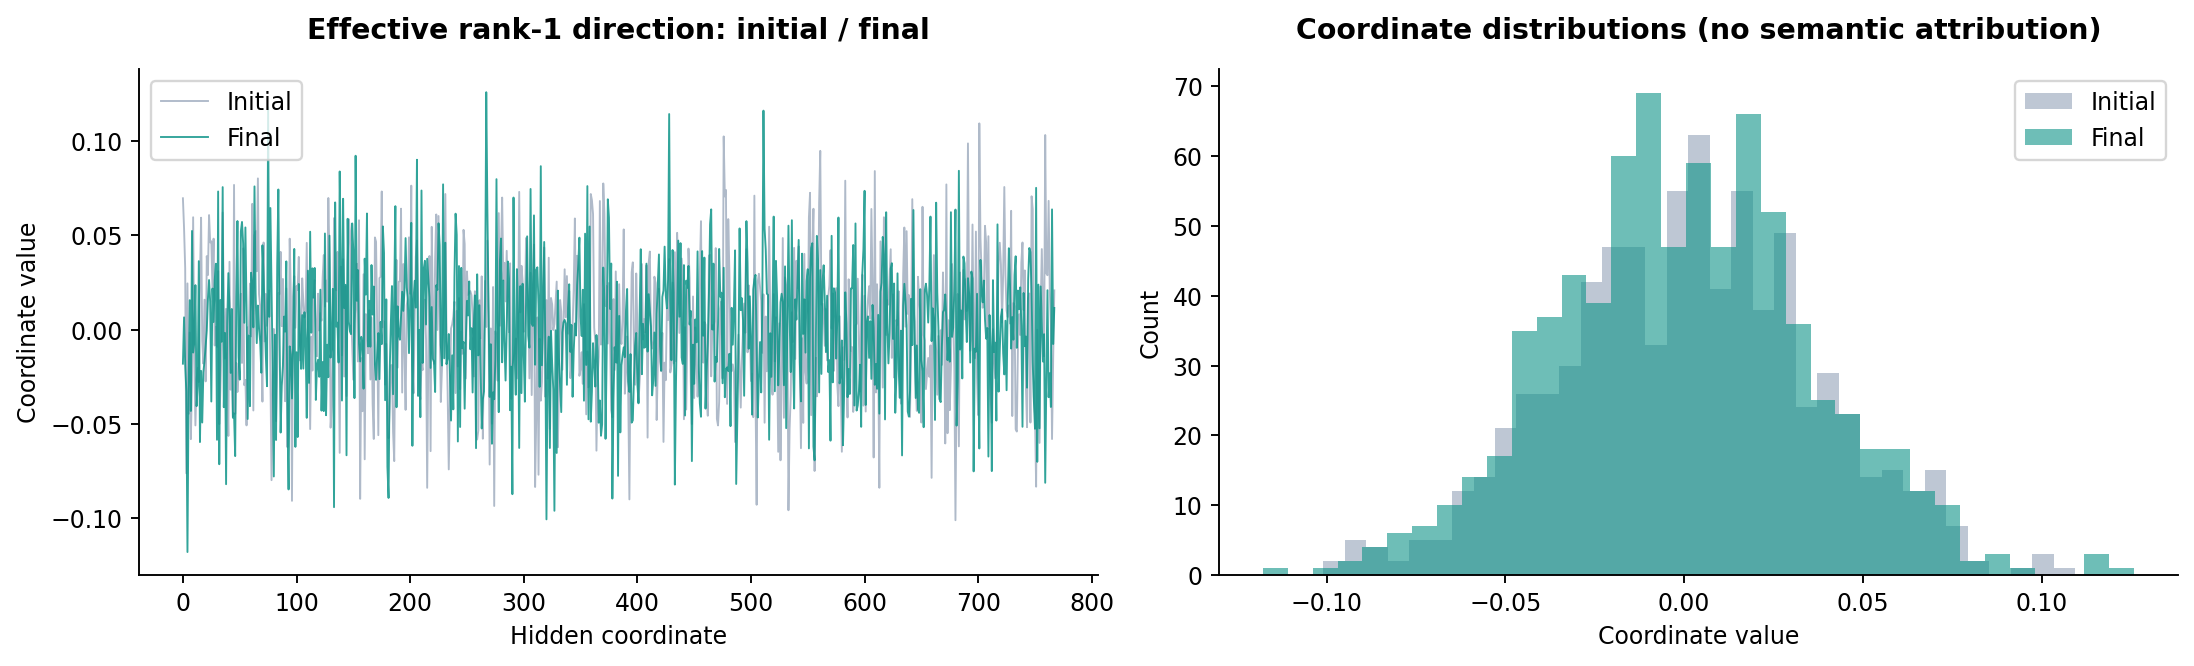

In [17]:
import torch
torch.set_num_threads(8)
initial_checkpoint = torch.load(RUN / "initial_alignment.pt", map_location="cpu", weights_only=True)
final_checkpoint = torch.load(RUN / "alignment.pt", map_location="cpu", weights_only=True)
intervention_key = next(iter(final_checkpoint["interventions"]))
def recover_direction(checkpoint):
    state = checkpoint["interventions"][intervention_key]
    original = state["rotate_layer.parametrizations.weight.original"]
    holder = torch.nn.Module()
    holder.register_parameter("weight", torch.nn.Parameter(torch.eye(*original.shape, dtype=original.dtype)))
    torch.nn.utils.parametrizations.orthogonal(holder)
    rotation_state = {name.removeprefix("rotate_layer."): tensor for name, tensor in state.items()
                      if name.startswith("rotate_layer.")}
    holder.load_state_dict(rotation_state, strict=True)
    return holder.weight.detach().cpu().numpy().reshape(-1)
initial_direction = recover_direction(initial_checkpoint)
final_direction = recover_direction(final_checkpoint)
stored_direction = final_checkpoint["effective_projection"][intervention_key].numpy().reshape(-1)
assert np.allclose(final_direction, stored_direction, atol=1e-6, rtol=1e-5)
assert np.isclose(np.linalg.norm(final_direction), 1, atol=1e-5)
signed_cosine = float(np.dot(initial_direction, final_direction) /
                      (np.linalg.norm(initial_direction) * np.linalg.norm(final_direction)))
geometry = {"dimensions": len(final_direction), "rank": 1,
            "initial_norm": float(np.linalg.norm(initial_direction)),
            "final_norm": float(np.linalg.norm(final_direction)),
            "signed_direction_cosine": signed_cosine,
            "sign_invariant_projector_overlap": signed_cosine ** 2,
            "max_reconstruction_error": float(np.max(np.abs(final_direction - stored_direction)))}
display(pd.DataFrame([geometry]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(initial_direction, color="#94a3b8", alpha=.75, lw=.8, label="Initial")
axes[0].plot(final_direction, color=COLORS["counterfactual"], alpha=.85, lw=.8, label="Final")
axes[0].set(title="Effective rank-1 direction: initial / final", xlabel="Hidden coordinate", ylabel="Coordinate value")
axes[0].legend()
axes[1].hist(initial_direction, bins=35, alpha=.6, color="#94a3b8", label="Initial")
axes[1].hist(final_direction, bins=35, alpha=.6, color=COLORS["counterfactual"], label="Final")
axes[1].set(title="Coordinate distributions (no semantic attribution)", xlabel="Coordinate value", ylabel="Count")
axes[1].legend()
fig.tight_layout()
show_figure(fig, "11_alignment_direction")

## 11. Validation: what was actually checked

Training success alone does not establish a correct intervention. The real
run checked identity, alignment gradients, every frozen model tensor's
bytes, full-vocabulary batch/individual agreement, independent positions
for unequal lengths, alignment reload, and hook/cache cleanup.

Batch/individual comparisons use combined absolute and relative tolerances,
not an absolute-error-only threshold. Synthetic examples below supplement
the original data; they never enter training or the IIA denominator.

In [18]:
trained_checks = validation["trained_identity_and_batching"]
frozen = validation["frozen_weights_and_alignment"]
validation_rows = [
    {"check": "Frozen model state", "passed": frozen["model_weights_bit_identical"],
     "evidence": "Full parameter/buffer SHA-256 before == after"},
    {"check": "Trainable alignment changed", "passed": frozen["alignment_changed"] and frozen["alignment_finite"],
     "evidence": ", ".join(frozen["changed_alignment_state_keys"])},
    {"check": "Identity", "passed": trained_checks["identity_intervention"]["status"] == "passed",
     "evidence": f"Max logit difference {trained_checks['identity_intervention']['max_absolute_difference']}"},
    {"check": "Alignment gradients", "passed": trained_checks["gradients"]["status"] == "passed",
     "evidence": f"Norm {trained_checks['gradients']['alignment_gradient_norm']}; no model gradients"},
    {"check": "Saved mixed-length batching", "passed": trained_checks["saved_data_mixed_length_batching"]["status"] == "passed",
     "evidence": "Full vocabulary allclose + matching argmax"},
    {"check": "Synthetic unequal lengths", "passed": all(v["status"] == "passed" for v in trained_checks["synthetic_unequal_length_batching"]["checks"].values()),
     "evidence": "18/22 and 22/18; N and N-2; readout always base N"},
    {"check": "Saved raw alignment reload", "passed": validation["saved_alignment_reload"]["logits_bit_identical"],
     "evidence": "Reloaded logits bit-identical; fresh projection recovery above"},
    {"check": "Hooks / caches cleaned", "passed": validation["cleanup"]["hooks_after"] == validation["cleanup"]["hooks_before"] and validation["cleanup"]["cached_activation_count"] == 0,
     "evidence": "No condition-owned hooks or cached activations remain"},
]
assert all(row["passed"] for row in validation_rows)
assert frozen["model_sha256_before"] == frozen["model_sha256_after"]
display(pd.DataFrame(validation_rows))
print("Frozen language-model SHA-256:", frozen["model_sha256_after"])
print("Recorded training GPU peak allocation (MiB):", result["gpu_peak_allocated_bytes"] / 2**20)
print("These are saved execution checks. The notebook does not rerun GPT-2.")

Frozen language-model SHA-256: 0a55e4d995d2759030f7d4c2f85983069c42db3bbc6b91e456cbf941dce43d1b
Recorded training GPU peak allocation (MiB): 672.92236328125
These are saved execution checks. The notebook does not rerun GPT-2.


,check,passed,evidence
0,Frozen model state,True,Full parameter/buffer SHA-256 before == after
1,Trainable alignment changed,True,layer_8_comp_block_output_unit_pos_nunit_1#0/r...
2,Identity,True,Max logit difference 0.0
3,Alignment gradients,True,Norm 1.0021908913053563; no model gradients
4,Saved mixed-length batching,True,Full vocabulary allclose + matching argmax
5,Synthetic unequal lengths,True,18/22 and 22/18; N and N-2; readout always base N
6,Saved raw alignment reload,True,Reloaded logits bit-identical; fresh projectio...
7,Hooks / caches cleaned,True,No condition-owned hooks or cached activations...


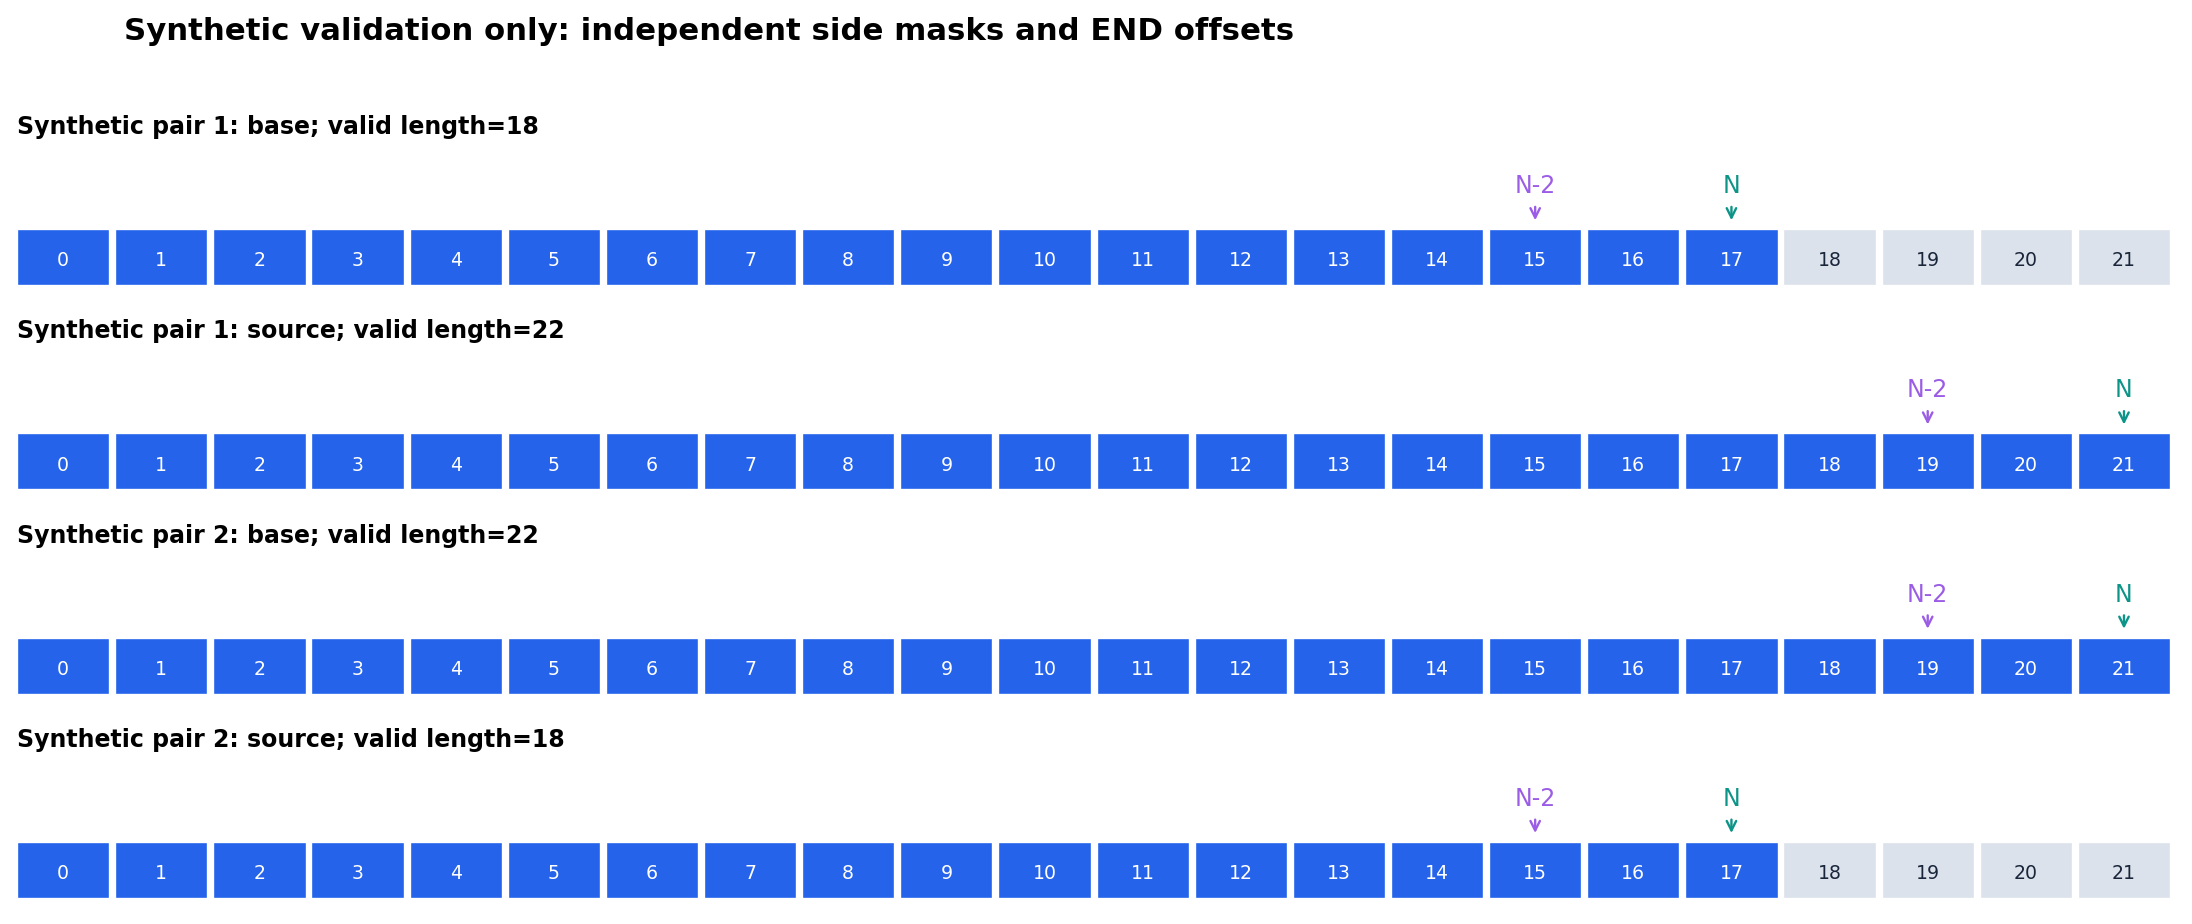

In [19]:
synthetic = trained_checks["synthetic_unequal_length_batching"]["checks"]
fig, axes = plt.subplots(4, 1, figsize=(13, 5.5))
row = 0
for example in range(2):
    for side in ("base", "source"):
        ax = axes[row]
        mask = synthetic["N"][f"{side}_attention_mask"][example]
        n = synthetic["N"][f"{side}_positions"][example]
        n_minus_two = synthetic["N-2"][f"{side}_positions"][example]
        for index, valid in enumerate(mask):
            ax.add_patch(Rectangle((index, 0), .95, .7, facecolor=COLORS["factual"] if valid else COLORS["padding"],
                                   edgecolor="white"))
            ax.text(index + .47, .32, str(index), ha="center", va="center", fontsize=8,
                    color="white" if valid else COLORS["ink"])
        ax.annotate("N", xy=(n + .47, .75), xytext=(n + .47, 1.15),
                    ha="center", color=COLORS["counterfactual"],
                    arrowprops={"arrowstyle": "->", "color": COLORS["counterfactual"]})
        ax.annotate("N-2", xy=(n_minus_two + .47, .75), xytext=(n_minus_two + .47, 1.15),
                    ha="center", color=COLORS["other"],
                    arrowprops={"arrowstyle": "->", "color": COLORS["other"]})
        ax.set_title(f"Synthetic pair {example + 1}: {side}; valid length={sum(mask)}", loc="left", fontsize=10)
        ax.set(xlim=(0, 22), ylim=(-.1, 1.5))
        ax.axis("off")
        row += 1
fig.suptitle("Synthetic validation only: independent side masks and END offsets", x=.06, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, .96))
show_figure(fig, "12_synthetic_unequal_positions")

## 12. What this run supports, and what remains unmeasured

- This is one condition and one initialization seed, not a layer/position sweep.
- All research examples are the saved original-rule samples. Source retains
  the base name multiset; unequal-length source/base cases are synthetic checks.
- Final train IIA includes identity pairs; test IIA uses cross-pattern pairs only.
- Test was not used for optimizer updates or selecting a best checkpoint.
- Initial test IIA, per-epoch test IIA, full top-k distributions, hidden
  activation vectors, and per-step alignment checkpoints were not saved.
- Accuracy is a full-vocabulary next-token argmax. Single-token answers are
  supported; multi-token cases are diagnosed by the implementation.
- The upstream quantity called kl_div is a mean target logit. It is not KL
  divergence, and this project labels it mean_target_logit.
- Direction sign and coordinate plots alone are not semantic explanations.

For the runnable experiment, inspect configs/phase2.json and the package
modules shown above. For handoff evidence, read docs/STATUS.md. Existing
experiment directories are protected against accidental overwrite.

In [20]:
overview = {
    "source_run": str(RUN), "source_result_sha256": sha256(RUN / "result.json"),
    "artifact_checks_passed": all(row["passed"] for row in checks),
    "metrics_recomputed_from_predictions": metric_table.to_dict(orient="records"),
    "test_outcomes": {name: int(value) for name, value in outcome_counts.items()},
    "alignment_geometry": geometry,
    "figure_names": figure_names,
    "language_model_loaded": False, "optimizer_updates_performed": 0,
    "sweep_started": False,
}
(FIGURES.parent / "overview.json").write_text(json.dumps(overview, indent=2, sort_keys=True) + "\n", encoding="utf-8")
figure_manifest = {f"{name}.{extension}": sha256(FIGURES / f"{name}.{extension}")
                   for name in figure_names for extension in ("png", "svg")}
(FIGURES.parent / "figure_manifest.json").write_text(
    json.dumps(figure_manifest, indent=2, sort_keys=True) + "\n", encoding="utf-8")
print(f"Complete walkthrough: {len(figure_names)} figures exported in PNG and SVG.")
print("Notebook exports:", FIGURES.parent)
print("No model weights loaded; no training or sweep performed.")

Complete walkthrough: 12 figures exported in PNG and SVG.
Notebook exports: /home/ilingl/projects/ioi-das-relative/outputs/notebooks/phase2_walkthrough
No model weights loaded; no training or sweep performed.
